# 10 · Machine Learning Fundamentals & Regression — Complete Reference

This notebook is the **regression half of DSMP's supervised-learning arc**. It
starts from "what actually is machine learning?" and ends with a working
end-to-end regression pipeline — covering every idea CampusX teaches between
sessions #144 and #175: the ML taxonomy, simple & multiple linear regression,
gradient descent in all its variants, statsmodels-style regression analysis,
the LINE assumptions, polynomial regression, multicollinearity & VIF, the three
families of feature selection, the bias–variance trade-off, and finally
Ridge / Lasso / ElasticNet regularization.

**How this maps to the playlist:** the sections follow playlist order — each
one carries a `▶` link back to the exact session it summarises, so you can
watch the video first and then use these notes as your revision sheet.

> **Note:** every code cell runs top-to-bottom in a fresh kernel with
> `random_state=42` — no internet needed, and all printed outputs are
> deterministic.

## ▶ Sessions covered

| # | Session | Video |
|---|---------|-------|
| 144 | Introduction to Machine Learning | https://www.youtube.com/watch?v=1ctqJCHMAmc |
| 145 | Simple Linear Regression | https://www.youtube.com/watch?v=aEPoLeS6UMM |
| 146 | Session 50 - Multiple Linear Regression | https://www.youtube.com/watch?v=e_9vJXokd-Y |
| 148 | Session on Optimization - The Big Picture | https://www.youtube.com/watch?v=T2f8249569Q |
| 149 | Session on Differential Calculus | https://www.youtube.com/watch?v=-siBIGUREjw |
| 150 | Gradient Descent From Scratch | https://www.youtube.com/watch?v=ORyfPJypKuU |
| 151 | Batch Gradient Descent with Code Demo | https://www.youtube.com/watch?v=Jyo53pAyVAM |
| 152 | Stochastic Gradient Descent | https://www.youtube.com/watch?v=V7KBAa_gh4c |
| 153 | Mini-Batch Gradient Descent | https://www.youtube.com/watch?v=_scscQ4HVTY |
| 155 | Session 1 on Regression Analysis | https://www.youtube.com/watch?v=qB5k6A60Unw |
| 157 | Session 2 on Regression Analysis | https://www.youtube.com/watch?v=6QQdhk2_H9Q |
| 158 | Polynomial Regression | https://www.youtube.com/watch?v=BNWLf3cKdbQ |
| 159 | Session on Assumptions of Linear Regression | https://www.youtube.com/watch?v=EWV9laVakjc |
| 160 | Session 53 - Multicollinearity | https://www.youtube.com/watch?v=XGJLWJ0a6aU |
| 161 | Session 54 - Feature Selection Part 1 \| Filter Methods | https://www.youtube.com/watch?v=hRTe7tSkR2k |
| 162 | Session 55 - Feature Selection Part 2 \| Wrapper Methods | https://www.youtube.com/watch?v=6-1WiITAW10 |
| 163 | Session 3 on Feature Selection \| Embedded Methods | https://www.youtube.com/watch?v=zLB-csjZ9V4 |
| 164 | Regularization Part 1 \| Bias Variance Trade-off | https://www.youtube.com/watch?v=qfWUIUvKi98 |
| 165 | Regularization Part 2 \| What is Regularization? | https://www.youtube.com/watch?v=cVsN5VAioz0 |
| 167 | Doubt Clearance Session on Regularization | https://www.youtube.com/watch?v=7_DDQkLzmRM |
| 169 | Ridge Regression Part 1 (Geometric Intuition) | https://www.youtube.com/watch?v=aEow1QoTLo0 |
| 170 | Ridge Regression Part 2 (Math + code from scratch) | https://www.youtube.com/watch?v=oDlZBQjk_3A |
| 171 | Ridge Regression Part 3 (Gradient Descent) | https://www.youtube.com/watch?v=Fci_wwMp8G8 |
| 172 | 5 Key Points - Ridge Regression Part 4 | https://www.youtube.com/watch?v=8osKeShYVRQ |
| 173 | Lasso Regression | https://www.youtube.com/watch?v=HLF4bFbBgwk |
| 174 | Why Lasso creates sparsity | https://www.youtube.com/watch?v=FN4aZPIAfI4 |
| 175 | ElasticNet Regression | https://www.youtube.com/watch?v=2g2DBkFhTTY |

In [1]:
%matplotlib inline

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson

SEED = 42

# NOTE: some macOS/BLAS + numpy 2.2 builds emit *phantom* RuntimeWarnings
# ("divide by zero / overflow / invalid encountered in matmul") for perfectly
# finite inputs once a matrix has more than ~200 rows — the results are
# correct, only the warning flags are wrong. Silence exactly those messages so
# the output stays readable (real numeric problems still surface elsewhere).
warnings.filterwarnings("ignore", message=r".*encountered in matmul")

print("imports OK — numpy", np.__version__, "| pandas", pd.__version__)


imports OK — numpy 2.2.6 | pandas 2.3.3


---
## 1. Machine learning fundamentals

▶ Session 144 – Introduction to Machine Learning: https://www.youtube.com/watch?v=1ctqJCHMAmc

**Definition.** Machine learning is the practice of writing programs that
*improve themselves with experience*. Instead of hard-coding `if size > 1000
then price = ...` rules, we feed the algorithm pairs of (inputs, known output)
and let it **estimate** the rule as a set of numeric parameters. A trained
model is just that: a handful of numbers (coefficients, weights, splits) that
were tuned to minimise error on the data it saw.

### The three families of learning

| Family | Supervision signal | Typical algorithms | Example problem |
|---|---|---|---|
| **Supervised** | labelled pairs $(X, y)$ | Linear/Logistic Regression, Decision Tree, KNN, SVM, Naive Bayes, Neural Nets | predict house price from size |
| **Unsupervised** | inputs $X$ only — no labels | K-Means, DBSCAN, PCA, Hierarchical Clustering, Apriori | customer segmentation |
| **Reinforcement** | scalar reward from an environment | Q-Learning, Policy Gradient, multi-armed bandits | game-playing agent, recommender |

### Classification vs regression (the two supervised tasks)

| | Classification | Regression |
|---|---|---|
| Target $y$ | discrete class / label | continuous real number |
| Question answered | *which* category? | *how much* / *how many*? |
| Model output | class label (or probability) | a number on the target's scale |
| Typical metrics | Accuracy, Precision/Recall, F1, ROC-AUC | MAE, RMSE, $R^2$ |
| DSMP example | spam vs not-spam | house price from area |

Everything in **this notebook is regression** — the target is always a number.
Classification gets its own notebook (`11_ml_classification.ipynb`).

### The supervised pipeline

```text
  raw data
     │
     ▼
 [EDA + preprocessing]  → clean X, encode categories, scale, handle outliers
     │
     ▼
 [train / validation / test split]  → test set is locked away until the end
     │
     ▼
 [fit model on TRAIN]  → estimate parameters (coefficients / weights)
     │
     ▼
 [evaluate on VALIDATION]  → tune hyper-parameters (α, degree, lr, max_depth…)
     │
     ▼
 [final honest number on TEST]  → what you report to the stakeholder
```

**Features vs target.** The **features** (predictors, independent variables,
matrix $X$) are the inputs; the **target** (dependent variable, vector $y$) is
the single column the model must predict. `n_samples` = rows, `n_features` =
columns of $X$.

### Why split at all?

A model evaluated on the very data it was trained on is like a student who
memorised the answer key — the score means nothing. The split gives us an
**honest estimate of generalisation error**:

| Split | Used for | Typical size |
|---|---|---|
| Train | fitting parameters | 60–80 % |
| Validation | choosing hyper-parameters, model comparison | 0–20 % |
| Test | final unbiased report — look at it ONCE | 20 % |

> **TIP:** if data is plentiful, 70/15/15 (train/val/test) is a fine default.
> If data is scarce, skip the separate validation split and use
> **cross-validation** (`cross_val_score`) inside the training set instead.

In [2]:
# --- classification split: stratify keeps the class mix identical ---
Xc, yc = make_classification(n_samples=500, n_features=8, n_informative=5,
                             n_redundant=1, random_state=SEED,
                             weights=[0.7, 0.3])

print("full set :", np.bincount(yc), "->", np.round(np.bincount(yc) / len(yc), 3))

Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.25,
                                      random_state=SEED, stratify=yc)
print("shapes   :", Xtr.shape, Xte.shape)
print("train    :", np.round(np.bincount(ytr) / len(ytr), 3))
print("test     :", np.round(np.bincount(yte) / len(yte), 3))

# NOTE: without stratify the rare class ratio drifts between train and test
Xtr2, Xte2, ytr2, yte2 = train_test_split(Xc, yc, test_size=0.25, random_state=SEED)
print("no stratify -> test:", np.round(np.bincount(yte2) / len(yte2), 3))

# --- regression split: no stratify (target is continuous) ---
Xr, yr = make_regression(n_samples=400, n_features=6, noise=15, random_state=SEED)
Xtr_r, Xte_r, ytr_r, yte_r = train_test_split(Xr, yr, test_size=0.2,
                                              random_state=SEED)
print("regression split:", Xtr_r.shape, Xte_r.shape)


full set : [347 153] -> [0.694 0.306]
shapes   : (375, 8) (125, 8)
train    : [0.693 0.307]
test     : [0.696 0.304]
no stratify -> test: [0.688 0.312]
regression split: (320, 6) (80, 6)


### `train_test_split(*arrays, test_size=None, train_size=None, random_state=None, shuffle=True, stratify=None)`
**What it does:** shuffles and slices one or more aligned arrays into
train/test pieces in a single call.
**Parameters:**
- `*arrays` — X, y (and any other parallel arrays); all must have the same first dimension
- `test_size` / `train_size` — float fraction or absolute count; give only one
- `random_state` — int seed → reproducible shuffle (**always set it**)
- `shuffle` — set `False` only for genuinely time-ordered data
- `stratify` — labels to keep proportionally in both splits (classification only)
**Returns:** list of the split arrays, in the order passed in.
**Example:** `Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)`

> **Gotcha — data leakage:** any statistic computed on the *whole* dataset
> *before* splitting (mean imputation, scaling, feature selection, target
> encoding) leaks test information into training. **Fit every transformer on
> `X_train` only, then `transform` both splits** — this is exactly what a
> `Pipeline` does for you (used throughout this notebook).

**Evaluation mindset.** One split gives one lucky/unlucky number; with small
data prefer k-fold cross-validation. Never iterate on the test set: each time
you look at test error and change the model, test error stops being an
unbiased estimate. And pick the metric *before* you start modelling — RMSE
punishes big mistakes, MAE is robust to outliers, $R^2$ is scale-free.

### Which algorithm family for which job?

| Family | Members | Task | Notebook |
|---|---|---|---|
| Linear models | Linear, Ridge, Lasso, ElasticNet | mostly regression | **this one** |
| Linear models | Logistic, SVM (linear) | classification | `11_ml_classification` |
| Tree-based | Decision Tree, Random Forest, XGBoost/LightGBM | both | tree notebooks |
| Instance-based | KNN | both | KNN notebook |
| Probabilistic | Naive Bayes | classification | NB notebook |
| Neural nets | MLP, CNN, RNN / Transformers | both | DL notebooks |
| Clustering | K-Means, DBSCAN, Hierarchical | unsupervised | clustering notebook |
| Dimensionality reduction | PCA, t-SNE, UMAP | unsupervised | PCA notebook |

### When **NOT** to use machine learning

1. **The rules are known and cheap to encode** — don't train a model to
   re-derive `tax = 0.05 * income`.
2. **Too little labelled data** — with 40 rows, hand-written rules or simple
   statistics usually win.
3. **The target leaks its own answer** — if a feature is recorded *after* the
   outcome, ML will happily cheat (e.g. "was the patient discharged?" used to
   predict recovery).
4. **Errors are catastrophic and hard to verify** — safety-critical systems
   need certified rules + human oversight, not a black box.
5. **You need a guaranteed-explainable decision** (some regulated domains).
6. **Nobody will maintain it** — an ML model degrades when data drifts; if
   there is no retraining budget, don't ship it.

**Section notes — ML fundamentals:**

| Concept | One-liner |
|---|---|
| Supervised | learns from labelled $(X, y)$ pairs |
| Unsupervised | structure in $X$ only |
| Reinforcement | learns from rewards |
| Regression vs classification | continuous target vs discrete label |
| train/test split | honest generalisation estimate |
| `stratify` | preserves class balance (classification only) |
| Leakage | fit transformers on train data ONLY |

---
## 2. Simple linear regression

▶ Session 145 – Simple Linear Regression: https://www.youtube.com/watch?v=aEPoLeS6UMM

### The model: $\hat{y} = b_0 + b_1 x$

- $b_1$ (**slope**) — how much $\hat y$ changes for a one-unit rise in $x$
- $b_0$ (**intercept**) — the prediction when $x = 0$

We fit it by minimising the **residual sum of squares**
$S(b_0, b_1) = \sum_{i=1}^{n}\big(y_i - b_0 - b_1 x_i\big)^2$ — the "least
squares" criterion.

**Derivation sketch (closed form).** Take partial derivatives and set them to
zero:

$$\frac{\partial S}{\partial b_0} = -2\sum_i (y_i - b_0 - b_1 x_i) = 0, \qquad
\frac{\partial S}{\partial b_1} = -2\sum_i x_i (y_i - b_0 - b_1 x_i) = 0$$

The first equation gives $b_0 = \bar y - b_1 \bar x$; substituting into the
second and rearranging gives the familiar formulas:

$$\boxed{\;b_1 = \frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sum_i (x_i-\bar x)^2}
= \frac{\operatorname{cov}(x,y)}{\operatorname{var}(x)},\qquad
b_0 = \bar y - b_1 \bar x\;}$$

Two facts worth memorising: the fitted line **always passes through
$(\bar x, \bar y)$**, and there is a *single* global optimum — no local minima
to worry about (the SSE surface is a convex paraboloid).

### `LinearRegression(fit_intercept=True, copy_X=True, n_jobs=None, positive=False)`
**What it does:** fits ordinary least squares — the coefficients that minimise
$\|y - X\beta\|^2$ — using SVD internally (it never explicitly inverts
$X^\top X$, which keeps it numerically safe).
**Syntax:** `LinearRegression().fit(X, y)`
**Parameters:**
- `fit_intercept` — bool — whether to fit $b_0$ (default `True`; set `False`
  if $X$ is already centred)
- `copy_X` — bool — copy the design matrix (default `True`)
- `n_jobs` — int — parallel jobs for fitting (`None`)
- `positive` — bool — constrain coefficients to be $\ge 0$ (default `False`)
**Returns:** the fitted estimator with attributes
- `.coef_` — array of slopes, one per feature
- `.intercept_` — scalar intercept $b_0$
- `.n_features_in_`, `.rank_`, `.singular_`
**Example:** below.

In [3]:
rng = np.random.default_rng(SEED)
x = rng.uniform(0, 1, 200)
y = 3.0 * x + 1.0 + rng.normal(0, 0.2, 200)

# --- from scratch: closed-form least squares ---
x_bar, y_bar = x.mean(), y.mean()
b1 = np.sum((x - x_bar) * (y - y_bar)) / np.sum((x - x_bar) ** 2)
b0 = y_bar - b1 * x_bar
print(f"scratch  : b0 = {b0:.4f}   b1 = {b1:.4f}")

# --- sklearn ---
slr = LinearRegression().fit(x.reshape(-1, 1), y)
print(f"sklearn  : intercept_ = {slr.intercept_:.4f}   coef_ = {slr.coef_[0]:.4f}")

# R² from scratch: 1 - SS_res / SS_tot
y_hat = b0 + b1 * x
ss_res = np.sum((y - y_hat) ** 2)
ss_tot = np.sum((y - y_bar) ** 2)
print(f"R² (scratch) = {1 - ss_res / ss_tot:.4f}   "
      f"R² (sklearn) = {r2_score(y, y_hat):.4f}")
# NOTE: true parameters were b0 = 1.0, b1 = 3.0 — noise makes us *estimate* them


scratch  : b0 = 0.9382   b1 = 3.1318
sklearn  : intercept_ = 0.9382   coef_ = 3.1318
R² (scratch) = 0.9513   R² (sklearn) = 0.9513


**R² intuition.** $R^2 = 1 - \dfrac{SS_{res}}{SS_{tot}}$ asks: *how much of
the target's variance does this line explain compared to just always
predicting $\bar y$?*

- $R^2 = 1$ → perfect fit
- $R^2 = 0$ → as good as the mean baseline
- $R^2 < 0$ → worse than the mean (possible on held-out data with a bad model)

### Error metrics every regression interview asks for

| Metric | Formula | Unit | Sensitivity |
|---|---|---|---|
| **MSE** | $\frac{1}{n}\sum (y_i-\hat y_i)^2$ | $y^2$ | heavily punishes big errors |
| **RMSE** | $\sqrt{\text{MSE}}$ | same as $y$ | interpretable version of MSE |
| **MAE** | $\frac{1}{n}\sum \|y_i-\hat y_i\|$ | same as $y$ | robust to outliers |
| **$R^2$** | $1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$ | unitless | variance explained |

In [4]:
mse = mean_squared_error(y, y_hat)
print(f"MSE  = {mse:.4f}")
print(f"RMSE = {np.sqrt(mse):.4f}   (same unit as y)")
print(f"MAE  = {mean_absolute_error(y, y_hat):.4f}")
print(f"R²   = {r2_score(y, y_hat):.4f}")
# TIP: MAE << RMSE signals a few large errors (outliers) in the data


MSE  = 0.0398
RMSE = 0.1996   (same unit as y)
MAE  = 0.1590
R²   = 0.9513


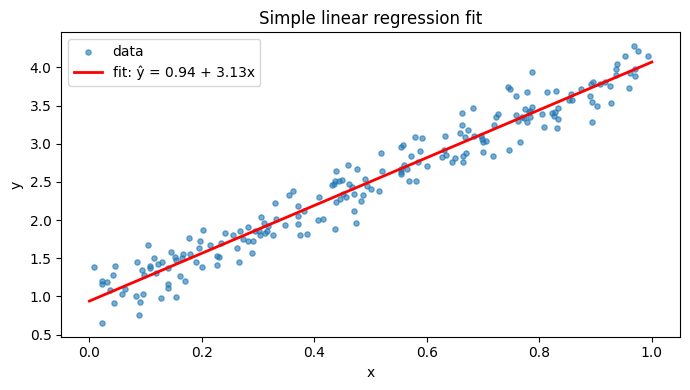

In [5]:
# fitted line over the data
grid = np.linspace(0, 1, 100).reshape(-1, 1)
plt.figure(figsize=(7, 4))
plt.scatter(x, y, s=14, alpha=0.6, label="data")
plt.plot(grid, slr.predict(grid), "r-", lw=2,
         label=f"fit: ŷ = {slr.intercept_:.2f} + {slr.coef_[0]:.2f}x")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Simple linear regression fit")
plt.legend(); plt.tight_layout(); plt.show()


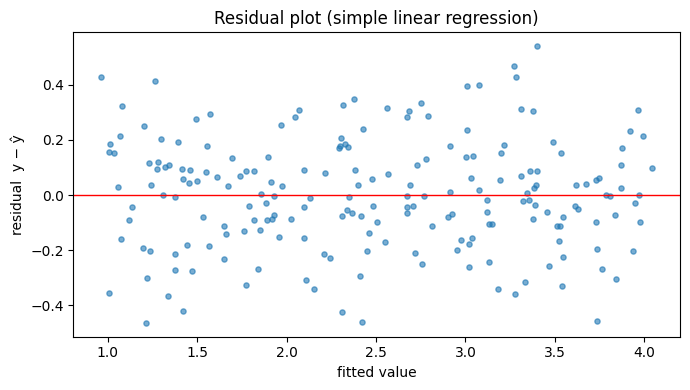

cor(fitted, residual) = 0.0


In [6]:
# residual plot: random scatter around 0 = the linear form is adequate
resid = y - slr.predict(x.reshape(-1, 1))
plt.figure(figsize=(7, 4))
plt.scatter(slr.predict(x.reshape(-1, 1)), resid, s=14, alpha=0.6)
plt.axhline(0, color="r", lw=1)
plt.xlabel("fitted value"); plt.ylabel("residual  y − ŷ")
plt.title("Residual plot (simple linear regression)")
plt.tight_layout(); plt.show()
print("cor(fitted, residual) =", round(np.corrcoef(slr.predict(x.reshape(-1, 1)), resid)[0, 1], 4))


> **Gotcha:** correlation is not causation, and $R^2$ does **not** prove the
> linear form is right — always look at the residual plot. A funnel or U shape
> means you should add features, transform $y$, or go polynomial (§9).

**Section notes — simple linear regression:**

| Item | Formula / code |
|---|---|
| Model | $\hat y = b_0 + b_1x$ |
| Slope | $b_1 = \sum(x-\bar x)(y-\bar y)/\sum(x-\bar x)^2$ |
| Intercept | $b_0 = \bar y - b_1\bar x$ |
| Fit (sklearn) | `LinearRegression().fit(X, y)` → `.coef_`, `.intercept_` |
| MSE / RMSE / MAE | `mean_squared_error`, `np.sqrt(...)`, `mean_absolute_error` |
| $R^2$ | `r2_score(y_true, y_pred)` |
| Diagnostics | residual vs fitted plot should be structureless noise |

---
## 3. Multiple linear regression

▶ Session 50 – Multiple Linear Regression: https://www.youtube.com/watch?v=e_9vJXokd-Y

### Matrix form

With $p$ features we stack everything into one equation:

$$Y = X\beta + \varepsilon,\qquad
X = \begin{bmatrix} 1 & x_{11} & \cdots & x_{1p}\\ \vdots & & & \vdots\\
1 & x_{n1} & \cdots & x_{np}\end{bmatrix},\quad
\beta = \begin{bmatrix} b_0\\ b_1\\ \vdots\\ b_p\end{bmatrix}$$

The closed-form solution is $\hat\beta = (X^\top X)^{-1} X^\top Y$ (the
*normal equations*). **sklearn never inverts this matrix** — it uses
least-squares/SVD, which survives near-singular $X$.

**Interpretation:** $b_j$ is the change in $\hat y$ for a one-unit rise in
$x_j$, *holding all other features fixed*. Because features live on different
scales, raw coefficients are not comparable — compute **standardized
coefficients** $\beta_j^{\text{std}} = \beta_j \cdot \operatorname{std}(x_j)$
(the effect of a 1-SD change) to rank feature importance.

**Assumptions preview (full diagnosis in §8 — the LINE mnemonic):**

| Letter | Assumption | Meaning |
|---|---|---|
| **L** | Linearity | $y$ is a linear function of the features |
| **I** | Independence | residuals are not correlated with each other |
| **N** | Normality | residuals are roughly normally distributed |
| **E** | Equal variance (homoscedasticity) | residual spread is constant |
| — | No perfect multicollinearity | no feature is a perfect linear combo of others |

In [7]:
X, y, coef_true = make_regression(n_samples=300, n_features=5, n_informative=3,
                                  noise=10, random_state=SEED, coef=True)
feat_names = ["area", "rooms", "age", "distance", "income"]
df = pd.DataFrame(X, columns=feat_names)
df["price"] = y
print(df.head())

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
mlr = LinearRegression().fit(Xtr, ytr)

# standardized coefficients: effect of a 1-SD change in the feature
scaler = StandardScaler().fit(Xtr)
std_coef = mlr.coef_ * scaler.scale_
report = pd.DataFrame({"raw_coef": mlr.coef_,
                       "std_coef": std_coef,
                       "true_coef": coef_true}, index=feat_names)
print(f"\nintercept_ = {mlr.intercept_:.4f}")
print(report.round(3))
# NOTE: age/distance have true_coef = 0 → their fitted coefs hover near 0 (noise)


       area     rooms       age  distance    income       price
0  0.504047 -0.530258 -0.985726  0.955142 -0.062679   27.171911
1  0.374057  1.227669 -1.993736  0.833529  0.330880  -28.978799
2  0.610370 -0.020902  0.747294 -0.560181 -0.828995  -30.334935
3 -0.689188  1.735964  2.075261  0.197600  1.317394  135.888864
4  0.624120  0.628346  0.791663  1.158111 -1.214189  103.106899

intercept_ = -0.0204
          raw_coef  std_coef  true_coef
area        -0.177    -0.170      0.000
rooms       -0.564    -0.546      0.000
age         50.616    48.501     49.826
distance    81.839    85.121     82.505
income      26.547    25.614     26.982


In [8]:
# predictions + full metrics table (train vs test → shows over/under-fitting)
def eval_regression(name, model, X_tr, y_tr, X_te, y_te):
    rows = {}
    for split, Xs, ys in [("train", X_tr, y_tr), ("test", X_te, y_te)]:
        pred = model.predict(Xs)
        n, k = len(ys), Xs.shape[1]
        r2 = r2_score(ys, pred)
        rows[f"{name} · {split}"] = {
            "MAE": mean_absolute_error(ys, pred),
            "MSE": mean_squared_error(ys, pred),
            "RMSE": np.sqrt(mean_squared_error(ys, pred)),
            "R2": r2,
            "adj_R2": 1 - (1 - r2) * (n - 1) / (n - k - 1),
        }
    return rows

metrics3 = pd.DataFrame(eval_regression("MLR", mlr, Xtr, ytr, Xte, yte)).T
print(metrics3.round(4))

# a single new house ...
new_house = np.array([[120.0, 3.0, 10.0, 5.0, 60.0]])
print("\npredicted price for", new_house[0], "=", round(float(mlr.predict(new_house)[0]), 2))


                MAE      MSE    RMSE      R2  adj_R2
MLR · train  7.5285  91.8341  9.5830  0.9917  0.9916
MLR · test   7.6207  97.4912  9.8738  0.9902  0.9893

predicted price for [120.   3.  10.   5.  60.] = 2485.24


**Metric formulas.**

$$\text{MAE}=\frac1n\sum|e_i|,\quad
\text{MSE}=\frac1n\sum e_i^2,\quad
\text{RMSE}=\sqrt{\text{MSE}},\quad
R^2 = 1-\frac{SS_{res}}{SS_{tot}},\quad
R^2_{adj} = 1-(1-R^2)\frac{n-1}{n-k-1}$$

| Metric | Pick it when… |
|---|---|
| MAE | outliers / heavy tails in $y$; you want "average miss" |
| MSE / RMSE | large errors must be punished hard; RMSE is interpretable |
| $R^2$ | you need a scale-free "variance explained" number |
| $R^2_{adj}$ | comparing models with *different numbers of features* (raw $R^2$ can only go up when you add a junk feature) |

> **Gotcha:** training $R^2$ ≥ test $R^2$ is normal; a *large* gap means
> overfitting (fix: more data, fewer features, or regularization — §12-15).
> If test $R^2$ is much lower and both are low, you are underfitting.

**Section notes — multiple linear regression:**

| Item | Code |
|---|---|
| Fit multi-feature model | `LinearRegression().fit(X, y)` |
| Coefficients | `.coef_` (per feature), `.intercept_` |
| Standardized coefs | `.coef_ * StandardScaler().fit(X).scale_` |
| Predict | `model.predict(X_new)` (X_new: same columns, same order!) |
| Compare models | train/test MAE, RMSE, $R^2$, $R^2_{adj}$ table |
| Normal equations | $\hat\beta=(X^\top X)^{-1}X^\top Y$ (sklearn uses SVD instead) |

---
## 4. Gradient descent — theory

▶ Session on Optimization - The Big Picture: https://www.youtube.com/watch?v=T2f8249569Q
▶ Session on Differential Calculus: https://www.youtube.com/watch?v=-siBIGUREjw

**The big picture.** Every machine-learning model is an optimisation problem:
*choose the parameters that make the predictions least wrong*. Gradient
descent (GD) is the general-purpose algorithm for that job — for linear
regression it has a closed form ($\hat\beta=(X^\top X)^{-1}X^\top Y$), but GD
generalises to models where **no closed form exists** (deep nets, logistic
regression with regularisers, …), so it is the one optimiser you must know.

```text
  ┌──────────────────────────────────────────────────────────┐
  │  start at random parameters   →   measure cost J(θ)      │
  │        │                                                   │
  │        ▼                                                   │
  │  compute gradient ∇J(θ)  (slope of J at θ)               │
  │        │                                                   │
  │        ▼                                                   │
  │  θ ← θ − η ∇J(θ)   (step DOWNHILL by learning rate η)     │
  │        │                                                   │
  │        └── repeat until J stops improving ─────────────┘
```

**Cost function for regression (MSE).** For the simple model
$\hat y = b_0 + b_1x$:

$$J(b_0, b_1) = \frac{1}{n}\sum_{i=1}^{n}\big(y_i - (b_0 + b_1 x_i)\big)^2$$

**Gradient — the partial derivatives written out:**

$$\frac{\partial J}{\partial b_0} = -\frac{2}{n}\sum_{i=1}^{n} (y_i - \hat y_i)
\qquad\qquad
\frac{\partial J}{\partial b_1} = -\frac{2}{n}\sum_{i=1}^{n} x_i\,(y_i - \hat y_i)$$

and in vector form for many features ($\varepsilon = y - X\beta$):

$$\nabla_\beta J = -\frac{2}{n} X^\top \varepsilon$$

**Update rule:**

$$\beta_j \leftarrow \beta_j - \eta \cdot \frac{\partial J}{\partial b_j}$$

**Learning rate $\eta$ controls everything:**

| $\eta$ | Behaviour |
|---|---|
| too small | crawls — thousands of iterations to converge |
| just right | steady downhill convergence |
| too large | overshoots, cost oscillates then **diverges** (∞) |

For MSE + linear model the cost surface is a convex bowl ⇒ exactly one
minimum; every learning-rate path leads there *if* $\eta$ is small enough
(roughly $\eta < 2/\lambda_{\max}$, where $\lambda_{\max}$ is the largest
eigenvalue of $\tfrac{2}{n}X^\top X$ — which is why scaling matters, below).

lr = 0.001 : final cost = 0.8745   b0 = 1.386  b1 = 0.891
lr = 0.01  : final cost = 0.1373   b0 = 1.518  b1 = 2.032
lr = 0.1   : final cost = 0.0398   b0 = 0.940  b1 = 3.128


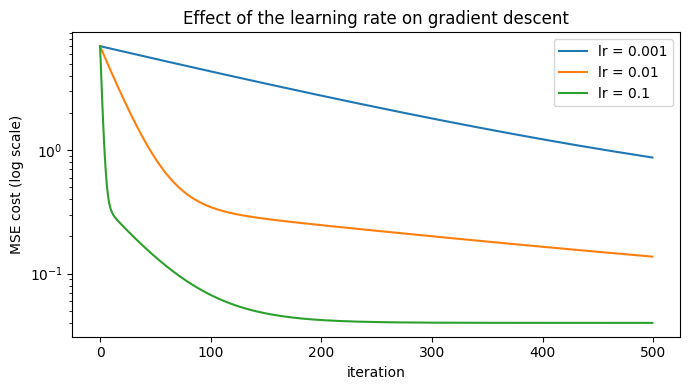

In [9]:
def run_gd_1d(x, y, lr, n_iter=500):
    """Plain batch gradient descent on y = b0 + b1*x. Returns params + cost history."""
    b0, b1 = 0.0, 0.0
    n = len(y)
    costs = []
    for _ in range(n_iter):
        err = y - (b0 + b1 * x)          # predict
        costs.append(np.mean(err ** 2))  # record cost
        b0 -= lr * (-2 / n) * np.sum(err)        # gradient wrt intercept
        b1 -= lr * (-2 / n) * np.sum(err * x)    # gradient wrt slope
    return b0, b1, costs

# rebuild the §2 dataset (same seed → identical data) so this cell is standalone
rng4g = np.random.default_rng(SEED)
x4g = rng4g.uniform(0, 1, 200)
y4g = 3.0 * x4g + 1.0 + rng4g.normal(0, 0.2, 200)

histories = {}
for lr in (0.001, 0.01, 0.1):
    b0_gd, b1_gd, c_gd = run_gd_1d(x4g, y4g, lr)
    histories[lr] = c_gd
    print(f"lr = {lr:<6}: final cost = {c_gd[-1]:.4f}   b0 = {b0_gd:.3f}  b1 = {b1_gd:.3f}")

plt.figure(figsize=(7, 4))
for lr, c_gd in histories.items():
    plt.plot(c_gd, label=f"lr = {lr}")
plt.yscale("log")
plt.xlabel("iteration"); plt.ylabel("MSE cost (log scale)")
plt.title("Effect of the learning rate on gradient descent")
plt.legend(); plt.tight_layout(); plt.show()
# NOTE: lr = 0.001 is still far from the optimum after 500 steps; lr = 0.1 gets
# there in tens of iterations. Divergence would show as the curve shooting UP.


### Batch vs Stochastic vs Mini-Batch

They differ in **how much data one gradient step uses**:

| Variant | Gradient uses | Updates per epoch | Gradient noise | Speed / behaviour | Memory |
|---|---|---|---|---|---|
| **Batch (BGD)** | the whole dataset | 1 | none — exact gradient | smooth, predictable, slow on big $n$ | whole $X$ at once |
| **Stochastic (SGD)** | 1 sample | $n$ | very high — zig-zag path | fast per update, can escape shallow minima, erratic | single row |
| **Mini-Batch (MBGD)** | $b$ samples (typ. 16–512) | $n/b$ | moderate | best of both — vectorised *and* noisy ⇒ the default everywhere | $b$ rows |

**Convergence criteria** (any of them — pick before you start):

1. **max iterations/epochs** reached,
2. **cost change** $|J_t - J_{t-1}| < \text{tol}$ (e.g. `1e-6`),
3. **gradient norm** $\|\nabla J\| < \text{tol}$ (we are flat → at a minimum),
4. **early stopping**: validation cost stops improving (also fights overfitting).

**Why feature scaling is mandatory before GD.** Each gradient component is
multiplied by its feature's magnitude, so a feature measured in *lakhs*
dominates every update and forces a tiny $\eta$ (otherwise you diverge). After
`StandardScaler()` all features are $\mathcal{O}(1)$ → gradients are
comparable → one sensible $\eta$ works and convergence is much faster.

UNSCALED features (x2 lives on [0, 50]):
   DIVERGED at iteration 5 (cost = 6.57e+15) — aborting
   survived 5 iterations, last cost = 2.692e+13
SCALED features:
   survived 300 iterations, last cost = 1.019 (noise floor ≈ 1.0)


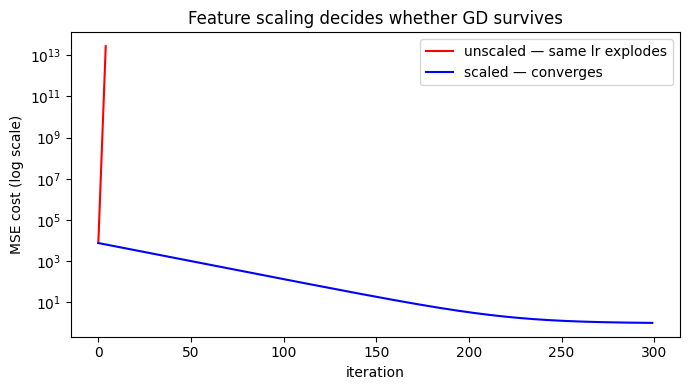

In [10]:
# Same learning rate, two very different worlds: raw vs scaled features
rng4 = np.random.default_rng(SEED)
x1s = rng4.uniform(0, 1, 200)
x2s = rng4.uniform(0, 50, 200)
X_scale = np.column_stack([x1s, x2s])
y_scale = 2 * x1s + 3 * x2s + rng4.normal(0, 1, 200)

def gd_linear(X, y, lr=0.01, n_iter=300, cost_cap=1e15):
    """Multi-feature batch GD; aborts if the cost explodes (divergence)."""
    n, p = X.shape
    w = np.zeros(p)
    b = 0.0
    costs = []
    for i in range(n_iter):
        err = y - (b + X @ w)
        cost = np.mean(err ** 2)
        if not np.isfinite(cost) or cost > cost_cap:
            print(f"   DIVERGED at iteration {i} (cost = {cost:.2e}) — aborting")
            break
        costs.append(cost)
        b -= lr * (-2 / n) * err.sum()
        w -= lr * ((-2 / n) * (X.T @ err))
    return costs, b, w

Xs_scaled = StandardScaler().fit_transform(X_scale)

print("UNSCALED features (x2 lives on [0, 50]):")
cost_raw, _, _ = gd_linear(X_scale, y_scale, lr=0.01)
print(f"   survived {len(cost_raw)} iterations, last cost = {cost_raw[-1]:.3e}")

print("SCALED features:")
cost_scl, b_s, w_s = gd_linear(Xs_scaled, y_scale, lr=0.01)
print(f"   survived {len(cost_scl)} iterations, last cost = {cost_scl[-1]:.3f} "
      f"(noise floor ≈ 1.0)")

plt.figure(figsize=(7, 4))
plt.plot(cost_raw, "r-", label="unscaled — same lr explodes")
plt.plot(cost_scl, "b-", label="scaled — converges")
plt.yscale("log")
plt.xlabel("iteration"); plt.ylabel("MSE cost (log scale)")
plt.title("Feature scaling decides whether GD survives")
plt.legend(); plt.tight_layout(); plt.show()


> **Gotcha:** you do not get a warning when gradient descent diverges — you
> just see `nan`/`inf` costs (or a model that predicts garbage). Always plot
> the cost history, and scale first.

**Section notes — GD theory:**

| Item | Formula / rule |
|---|---|
| Cost (MSE) | $J=\frac1n\sum (y_i-\hat y_i)^2$ |
| Update | $\beta \leftarrow \beta - \eta\nabla J$ |
| $\partial J/\partial b_0$ | $-\frac2n\sum (y_i-\hat y_i)$ |
| $\partial J/\partial b_1$ | $-\frac2n\sum x_i(y_i-\hat y_i)$ |
| Learning rate | too small → crawl; too large → diverge |
| Before GD | **always** `StandardScaler()` |
| Stop when | max iters / $\Delta J<$ tol / early stopping |

---
## 5. Gradient descent — from-scratch code

▶ Gradient Descent From Scratch: https://www.youtube.com/watch?v=ORyfPJypKuU
▶ Batch Gradient Descent with Code Demo: https://www.youtube.com/watch?v=Jyo53pAyVAM
▶ Stochastic Gradient Descent: https://www.youtube.com/watch?v=V7KBAa_gh4c
▶ Mini-Batch Gradient Descent: https://www.youtube.com/watch?v=_scscQ4HVTY

**Batch GD — pseudocode** (what the cell below implements literally):

```text
w ← 0 (or random), b ← 0
repeat n_iter times:
    pred  ← b + X @ w                 # 1. predict
    err   ← y − pred                  # 2. error
    grad_w ← −(2/n) · Xᵀ @ err        # 3. gradient
    grad_b ← −(2/n) · Σ err
    w ← w − lr · grad_w               # 4. update
    b ← b − lr · grad_b
    record  mean(err²)                 # cost history
```

final cost = 57.847  (started at 13611.3)
intercept : 0.451
weights   : [85.724 81.833 14.435]
true coefs: [83.213 81.797 16.076]  ← weights must match (X was z-scored ⇒ coef × std)


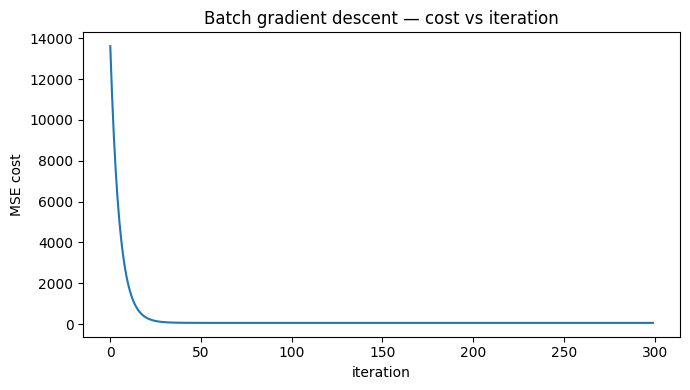

In [11]:
# shared data: 3 features, standardised (see §4 — scale before GD)
Xd5, yd5, coef5 = make_regression(n_samples=300, n_features=3, n_informative=3,
                                  noise=8, random_state=SEED, coef=True)
Xz5 = StandardScaler().fit_transform(Xd5)

def batch_gd(X, y, lr=0.05, n_iter=300):
    """Full-batch gradient descent — one update per pass over ALL rows."""
    n, p = X.shape
    w = np.zeros(p)
    b = 0.0
    costs = []
    for _ in range(n_iter):
        err = y - (b + X @ w)                       # predict + error
        costs.append(np.mean(err ** 2))             # cost history
        grad_w = (-2 / n) * (X.T @ err)             # gradient
        grad_b = (-2 / n) * err.sum()
        w -= lr * grad_w                            # update
        b -= lr * grad_b
    return b, w, costs

b_bgd, w_bgd, costs_bgd = batch_gd(Xz5, yd5, lr=0.05, n_iter=300)
print(f"final cost = {costs_bgd[-1]:.3f}  (started at {costs_bgd[0]:.1f})")
print("intercept :", round(b_bgd, 3))
print("weights   :", np.round(w_bgd, 3))
print("true coefs:", np.round(coef5, 3),
      " ← weights must match (X was z-scored ⇒ coef × std)")

plt.figure(figsize=(7, 4))
plt.plot(costs_bgd)
plt.xlabel("iteration"); plt.ylabel("MSE cost")
plt.title("Batch gradient descent — cost vs iteration")
plt.tight_layout(); plt.show()


**Stochastic vs mini-batch.** The only difference is the slice used for each
update:

```text
SGD       : for each single row i:        w ← w − lr · ∇J({i})
Mini-batch: for each slice X[b:b+BS]:     w ← w − lr · ∇J({b … b+BS})
```

Both shuffle the data at the start of every **epoch** (one full pass). Because
a single sample is a noisy estimate of the true gradient, SGD needs a smaller
learning rate but takes many cheap steps; mini-batch (here `batch_size=16`)
averages 16 rows → less noise while staying vectorised.

cost after 100 epochs
  batch      : 57.847
  stochastic : 58.112
  mini-batch : 57.991

learned weights (batch / sgd / mini-batch):
  [85.72 81.83 14.43]
  [85.63 82.17 14.08]
  [85.68 82.14 14.21]


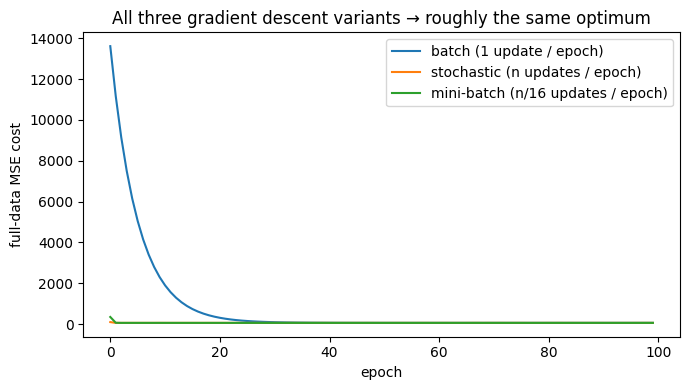

In [12]:
def sgd_gd(X, y, lr=0.005, epochs=100, seed=SEED):
    """Stochastic GD — one parameter update per training sample."""
    n, p = X.shape
    w = np.zeros(p)
    b = 0.0
    rg = np.random.default_rng(seed)
    costs = []
    for _ in range(epochs):
        for i in rg.permutation(n):                 # shuffle each epoch
            err_i = y[i] - (w @ X[i] + b)           # single-sample error
            b += lr * 2 * err_i
            w += lr * 2 * err_i * X[i]
        costs.append(np.mean((y - (b + X @ w)) ** 2))  # full-data cost per epoch
    return b, w, costs

def minibatch_gd(X, y, lr=0.05, epochs=100, batch_size=16, seed=SEED):
    """Mini-batch GD — one update per batch_size rows."""
    n, p = X.shape
    w = np.zeros(p)
    b = 0.0
    rg = np.random.default_rng(seed)
    costs = []
    for _ in range(epochs):
        idx = rg.permutation(n)
        for s in range(0, n, batch_size):
            batch = idx[s:s + batch_size]
            Xb, yb_ = X[batch], y[batch]
            m = len(batch)
            err = yb_ - (b + Xb @ w)
            b -= lr * (-2 / m) * err.sum()
            w -= lr * ((-2 / m) * (Xb.T @ err))
        costs.append(np.mean((y - (b + X @ w)) ** 2))
    return b, w, costs

b_sgd, w_sgd, costs_sgd = sgd_gd(Xz5, yd5, lr=0.005, epochs=100)
b_mb, w_mb, costs_mb = minibatch_gd(Xz5, yd5, lr=0.05, epochs=100, batch_size=16)

# batch cost is recorded per iteration; re-run it epoch-style for a fair x-axis
_, _, costs_bgd_ep = batch_gd(Xz5, yd5, lr=0.05, n_iter=100)

print("cost after 100 epochs")
print(f"  batch      : {costs_bgd_ep[-1]:.3f}")
print(f"  stochastic : {costs_sgd[-1]:.3f}")
print(f"  mini-batch : {costs_mb[-1]:.3f}")
print("\nlearned weights (batch / sgd / mini-batch):")
print(" ", np.round(w_bgd, 2))
print(" ", np.round(w_sgd, 2))
print(" ", np.round(w_mb, 2))

plt.figure(figsize=(7, 4))
plt.plot(costs_bgd_ep, label="batch (1 update / epoch)")
plt.plot(costs_sgd, label="stochastic (n updates / epoch)")
plt.plot(costs_mb, label="mini-batch (n/16 updates / epoch)")
plt.xlabel("epoch"); plt.ylabel("full-data MSE cost")
plt.title("All three gradient descent variants → roughly the same optimum")
plt.legend(); plt.tight_layout(); plt.show()
# NOTE: SGD zig-zags (each step sees 1 row) but the three curves settle at the
# same cost — same objective, different paths.


**Section notes — GD code:**

| Variant | Core loop | Key parameter |
|---|---|---|
| Batch | error over all rows → 1 update | `n_iter` |
| Stochastic | error of 1 row → update, shuffle each epoch | `lr` (must be small) |
| Mini-batch | error over `batch_size` rows → update | `batch_size` (16–512) |

> **Gotcha:** comparing "iteration" counts across variants is meaningless —
> one SGD epoch = $n$ updates. Always compare **epochs** (passes over data)
> or **wall-clock time**.

---
## 6. Gradient descent variants — which one when?

▶ Batch Gradient Descent with Code Demo: https://www.youtube.com/watch?v=Jyo53pAyVAM
▶ Stochastic Gradient Descent: https://www.youtube.com/watch?v=V7KBAa_gh4c
▶ Mini-Batch Gradient Descent: https://www.youtube.com/watch?v=_scscQ4HVTY

| Variant | Use when | Watch out for |
|---|---|---|
| **Batch GD** | $n$ is small–medium; you want smooth, reproducible convergence; convex cost (linear/logistic regression) | each step costs a full pass over the data |
| **SGD** | $n$ so large it does not fit in memory; online/streaming data; you *want* noise to escape shallow local minima | high variance in the cost curve; needs LR scheduling |
| **Mini-batch** | **the default in practice** — GPUs/BLAS love batches of 32–512 | batch size is one more hyper-parameter |

In scikit-learn the SGD family is exposed as `SGDRegressor` /
`SGDClassifier` (linear model + SGD optimiser), e.g.
`SGDRegressor(loss="squared_error", penalty="l2", random_state=42)`.

### Optimiser upgrades (one-liner preview — coded in deep-learning notebooks)

- **Momentum:** keeps a velocity $v \leftarrow \beta v - \eta\nabla J$ with
  $\beta\approx0.9$ — accelerates along consistent directions, dampens
  oscillation across ravines.
- **RMSProp:** scales the step by $1/\sqrt{\text{running mean of } \nabla J^2}$
  — adapts LR per parameter.
- **Adam:** momentum + RMSProp in one ($\beta_1=0.9$, $\beta_2=0.999$) — the
  default optimiser for neural networks; rarely needed for regression.

**Rule of thumb:** linear/logistic regression on tabular data → sklearn's
closed-form/solver; large-scale linear models → mini-batch SGD; deep learning
→ Adam.

**Section notes — variants:**

| Question | Answer |
|---|---|
| How do BGD/SGD/MBGD differ? | size of the row slice per gradient step |
| Which is default? | mini-batch |
| Compare fairly? | by epochs (full passes), not iterations |
| First upgrade after plain GD? | momentum, then Adam |

---
## 7. Regression analysis with statsmodels

▶ Session 1 on Regression Analysis: https://www.youtube.com/watch?v=qB5k6A60Unw
▶ Session 2 on Regression Analysis: https://www.youtube.com/watch?v=6QQdhk2_H9Q

scikit-learn optimises for **prediction**; **statsmodels** optimises for
**inference** — standard errors, p-values, confidence intervals and a full
diagnostic report in one `summary()`. Both fit the *same* OLS coefficients;
they differ in what they hand back.

### `sm.OLS(endog, exog)`
**What it does:** ordinary least squares with inferential statistics attached.
**Syntax:** `sm.OLS(y, sm.add_constant(X)).fit()`
**Parameters:**
- `endog` — array/Series — dependent variable $y$
- `exog` — array/DataFrame — design matrix $X$. **You must add the intercept
  column yourself** with `sm.add_constant(X)` — statsmodels fits *no* intercept
  by default (a classic source of silently wrong results).
**Returns:** an `OLSResults` object with `.params`, `.bse`, `.pvalues`,
`.conf_int()`, `.rsquared`, `.fittedvalues`, `.resid`, `.summary()`, …
**Example:** below.

In [13]:
X7, y7, _ = make_regression(n_samples=300, n_features=5, n_informative=3,
                            noise=10, random_state=SEED, coef=True)
X7tr, X7te, y7tr, y7te = train_test_split(X7, y7, test_size=0.2, random_state=SEED)

X7sm = sm.add_constant(X7tr)              # prepend the 1s column (intercept)
ols = sm.OLS(y7tr, X7sm).fit()
print(ols.summary())


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.992
Model:                            OLS   Adj. R-squared:                  0.992
Method:                 Least Squares   F-statistic:                     5610.
Date:                Wed, 07 Oct 2026   Prob (F-statistic):          2.21e-241
Time:                        22:58:34   Log-Likelihood:                -882.94
No. Observations:                 240   AIC:                             1778.
Df Residuals:                     234   BIC:                             1799.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0204      0.637     -0.032      0.9

**How to read `summary()` — field by field.**

| Block | Field | Meaning | Healthy look |
|---|---|---|---|
| Top | `R-squared` | variance explained, $1-SS_{res}/SS_{tot}$ | close to 1 |
| Top | `Adj. R-squared` | $R^2$ penalised for $k$ features — use it to compare models with different $k$ | ≈ `R-squared` |
| Top | `F-statistic` / `Prob (F)` | joint test $H_0$: *all* slope coefficients are 0 | `Prob (F)` ≈ 0 |
| Coef table | `coef` | OLS estimate $\hat\beta_j$ | sign/magnitude as expected |
| Coef table | `std err` | uncertainty of $\hat\beta_j$ | small vs `coef` |
| Coef table | `t` | $t_j = \text{coef}_j / \text{std err}_j$ | \|t\| > 2 |
| Coef table | `P>\|t\|` | p-value of $H_0:\beta_j=0$ | < 0.05 → reject $H_0$ |
| Coef table | `[0.025  0.975]` | 95 % confidence interval for $\beta_j$ | excludes 0 ⇒ significant |
| Bottom | `Durbin-Watson` | residual autocorrelation: ≈2 none, <1 positive, >3 negative | 1.5–2.5 |
| Bottom | `Jarque-Bera` / `Prob(JB)` | normality of residuals (skew 0, kurtosis 3) | `Prob(JB)` > 0.05 |
| Bottom | `Cond. No.` | condition number of $X$ — very large (≫ 1000) ⇒ multicollinearity or unscaled features (§10) | small |
| Bottom | `AIC` / `BIC` | fit penalised by parameter count — lower wins when comparing models | lower |

> **Interview line:** *"I check `Prob(F)` first (is the model useful at all?),
> then individual `P>\|t\|` (which features matter?), then `Adj. R²` (how much
> variance is explained after penalty?), and the diagnostics at the bottom
> (Durbin-Watson, Jarque-Bera, Cond. No.) to verify the assumptions."*

In [14]:
# confidence intervals for params + prediction vs confidence interval
print("95% confidence intervals for the coefficients (same as summary):")
print(ols.conf_int(alpha=0.05).round(3))

# new house: [const, area, rooms, age, distance, income]
# NOTE: has_constant="add" — with a single row statsmodels sees every column
# as "constant" and would skip adding the intercept otherwise.
X_new = sm.add_constant(np.array([[120.0, 3.0, 10.0, 5.0, 60.0]]),
                        has_constant="add")
pred = ols.get_prediction(X_new)
print("\nprediction for one new observation:")
print(pred.summary_frame(alpha=0.05).round(3))
# NOTE: mean_ci_* = confidence interval for the MEAN response (narrow);
#       obs_ci_*  = prediction interval for a NEW observation (always wider —
#       it also contains the irreducible noise σ²).


95% confidence intervals for the coefficients (same as summary):
[[-1.275  1.234]
 [-1.468  1.114]
 [-1.852  0.723]
 [49.318 51.914]
 [80.642 83.035]
 [25.256 27.839]]

prediction for one new observation:
      mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  2485.24   84.338       2319.082       2651.398      2317.985      2652.495


In [15]:
# Log-transformation: fixing a badly skewed target
rng7 = np.random.default_rng(SEED)
x_sk = rng7.normal(0, 1, 400)
y_sk = np.exp(0.8 * x_sk) * np.random.default_rng(7).lognormal(0, 0.4, 400)

ols_raw = sm.OLS(y_sk, sm.add_constant(x_sk)).fit()
ols_log = sm.OLS(np.log(y_sk), sm.add_constant(x_sk)).fit()

print(f"raw model  : target skew = {stats.skew(y_sk):8.3f}   "
      f"residual JB p-value = {stats.jarque_bera(ols_raw.resid)[1]:.3f}")
print(f"log model  : target skew = {stats.skew(np.log(y_sk)):8.3f}   "
      f"residual JB p-value = {stats.jarque_bera(ols_log.resid)[1]:.3f}")
print("\nlog-model params (1 unit of x MULTIPLIES y by exp(b1)):")
print(pd.Series(ols_log.params, index=["const", "x"]).round(3))
print("multiplier for +1 in x:", round(float(np.exp(ols_log.params[1])), 3))
# TIP: after a log target, report exp(b1)-style effects (percent change),
# and back-transform predictions with np.exp(pred) (add a smearing correction
# for unbiased means).


raw model  : target skew =    4.288   residual JB p-value = 0.000
log model  : target skew =    0.107   residual JB p-value = 0.829

log-model params (1 unit of x MULTIPLIES y by exp(b1)):
const   -0.042
x        0.785
dtype: float64
multiplier for +1 in x: 2.192


**Section notes — statsmodels:**

| Item | Code |
|---|---|
| Fit OLS | `sm.OLS(y, sm.add_constant(X)).fit()` |
| Full report | `ols.summary()` |
| Coefficients / p-values | `ols.params`, `ols.pvalues`, `ols.bse` |
| 95 % CIs | `ols.conf_int(alpha=0.05)` |
| Mean & prediction intervals | `ols.get_prediction(X_new).summary_frame()` |
| Skewed $y$ | `sm.OLS(np.log(y), ...)` → multiplicative interpretation |

> **Gotcha:** `sm.OLS` does **not** add an intercept. Forgetting
> `sm.add_constant()` fits a line through the origin and inflates $R^2$
> comparisons — always check `ols.params` has a `const` entry.

---
## 8. Assumptions of linear regression (LINE)

▶ Session on Assumptions of Linear Regression: https://www.youtube.com/watch?v=EWV9laVakjc

OLS coefficients are the *best linear unbiased estimators* only if the
**LINE** assumptions hold. When they break, predictions can still be decent —
but **p-values, confidence intervals and hypothesis tests become untrustworthy**.

| # | Assumption | Statement | Diagnosed with |
|---|---|---|---|
| **L** | Linearity | $y$ is a linear function of the features | residual vs fitted plot |
| **I** | Independence | residuals are uncorrelated with each other | Durbin-Watson statistic |
| **N** | Normality | residuals $\sim \mathcal N(0,\sigma^2)$ | histogram + Q-Q plot, Jarque-Bera |
| **E** | Equal variance | residual spread constant across fitted values | residual vs fitted, scale-location plot |
| — | No perfect multicollinearity | no exact linear relation among features | VIF, condition number (§10) |

The cell below builds a small well-behaved dataset, then **diagnoses each
assumption with its own test** — run the checks in order, exactly as you would
on a real project.

In [16]:
rng8 = np.random.default_rng(SEED)
X8 = rng8.normal(0, 1, (200, 2))
y8 = 3 * X8[:, 0] - 2 * X8[:, 1] + 1 + rng8.normal(0, 0.5, 200)

X8tr, X8te, y8tr, y8te = train_test_split(X8, y8, test_size=0.25, random_state=SEED)
m8 = LinearRegression().fit(X8tr, y8tr)
fit8 = m8.predict(X8tr)
resid8 = y8tr - fit8
z8 = resid8 / resid8.std()          # standardised residuals
print("model:", f"ŷ = {m8.intercept_:.2f} + {m8.coef_[0]:.2f}·x1 + {m8.coef_[1]:.2f}·x2")
print(f"residual mean = {resid8.mean():.3f}  std = {resid8.std():.3f}")


model: ŷ = 0.93 + 2.95·x1 + -1.99·x2
residual mean = -0.000  std = 0.503


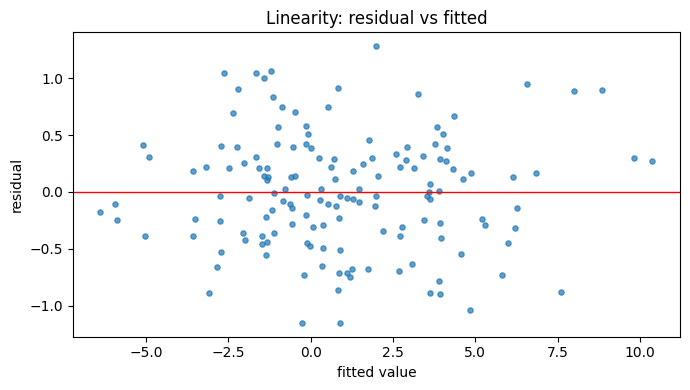

cor(fitted, residual) = -0.0000  →  PASS (no pattern)


In [17]:
# (L) LINEARITY — residual vs fitted must be structureless cloud around 0
corr_lf = np.corrcoef(fit8, resid8)[0, 1]
plt.figure(figsize=(7, 4))
plt.scatter(fit8, resid8, s=14, alpha=0.7)
plt.axhline(0, color="r", lw=1)
plt.xlabel("fitted value"); plt.ylabel("residual")
plt.title("Linearity: residual vs fitted")
plt.tight_layout(); plt.show()
print(f"cor(fitted, residual) = {corr_lf:.4f}  →  "
      f"{'PASS (no pattern)' if abs(corr_lf) < 0.1 else 'FAIL (pattern present)'}")


In [18]:
# (I) INDEPENDENCE — Durbin-Watson on the residuals (in train ROW order)
dw8 = durbin_watson(resid8)
verdict = "PASS" if 1.5 < dw8 < 2.5 else "FAIL"
print(f"Durbin-Watson = {dw8:.3f}   (2 = no autocorrelation, 0 = positive, 4 = negative)")
print(f"verdict: {verdict} — 1.5 < DW < 2.5 is the usual rule of thumb")
# NOTE: for time series, order rows by time first — a random shuffle destroys
# the very autocorrelation DW is meant to detect.


Durbin-Watson = 1.939   (2 = no autocorrelation, 0 = positive, 4 = negative)
verdict: PASS — 1.5 < DW < 2.5 is the usual rule of thumb


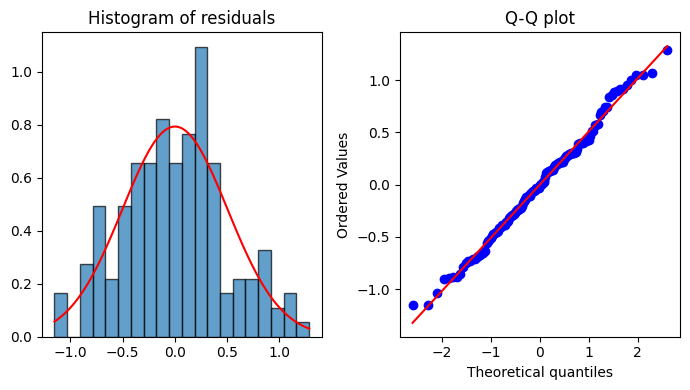

Jarque-Bera: stat = 0.800, p-value = 0.670 → PASS (residuals look normal)


In [19]:
# (N) NORMALITY — histogram + Q-Q plot + Jarque-Bera
jb_stat, jb_p = stats.jarque_bera(resid8)
fig, axes = plt.subplots(1, 2, figsize=(7, 4))
axes[0].hist(resid8, bins=20, edgecolor="black", alpha=0.7, density=True)
xs_g = np.linspace(resid8.min(), resid8.max(), 100)
axes[0].plot(xs_g, stats.norm.pdf(xs_g, resid8.mean(), resid8.std()), "r-")
axes[0].set_title("Histogram of residuals")
stats.probplot(resid8, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot")
plt.tight_layout(); plt.show()
print(f"Jarque-Bera: stat = {jb_stat:.3f}, p-value = {jb_p:.3f} → "
      f"{'PASS (residuals look normal)' if jb_p > 0.05 else 'FAIL (non-normal)'}")


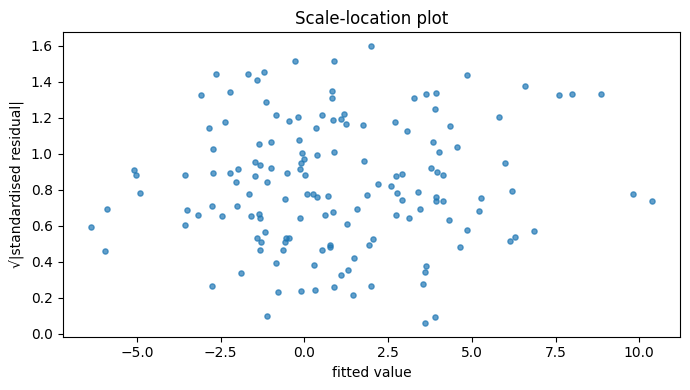

cor(fitted, √|z-resid|) = 0.0626 → PASS (constant spread)


In [20]:
# (E) HOMOSCEDASTICITY — spread of |standardised residuals| vs fitted (scale-location)
plt.figure(figsize=(7, 4))
plt.scatter(fit8, np.sqrt(np.abs(z8)), s=14, alpha=0.7)
plt.xlabel("fitted value"); plt.ylabel("√|standardised residual|")
plt.title("Scale-location plot")
plt.tight_layout(); plt.show()
corr_hc = np.corrcoef(fit8, np.sqrt(np.abs(z8)))[0, 1]
print(f"cor(fitted, √|z-resid|) = {corr_hc:.4f} → "
      f"{'PASS (constant spread)' if abs(corr_hc) < 0.15 else 'FAIL (funnel shape)'}")


In [21]:
# (no perfect MULTICOLLINEARITY) — quick pair-correlation + condition number
pair_corr = np.max(np.abs(np.corrcoef(X8tr, rowvar=False) - np.eye(2)))
cond8 = np.linalg.cond(sm.add_constant(X8tr))
print(f"max |feature correlation| = {pair_corr:.3f}  → {'PASS' if pair_corr < 0.9 else 'FAIL'}")
print(f"condition number of X     = {cond8:.1f}  → "
      f"{'PASS' if cond8 < 1000 else 'FAIL (scale or collinearity problem)'}")
print("(full multicollinearity diagnosis with VIF in §10)")


max |feature correlation| = 0.080  → PASS
condition number of X     = 1.1  → PASS
(full multicollinearity diagnosis with VIF in §10)


**Fixes when an assumption fails:**

| Violation | Diagnostic symptom | Fix |
|---|---|---|
| Linearity | curved pattern in residual plot | add polynomial/interaction features, log/sqrt transforms, add missing predictors |
| Independence | DW far from 2 (time series) | include lag features, use ARIMA/mixed models, cluster-robust standard errors |
| Normality | skewed histogram, funnel Q-Q, JB p < 0.05 | transform $y$ (`log`, `sqrt`), collect more data (CLT), use bootstrap CIs |
| Homoscedasticity | funnel in residual plot, scale-location slope ≠ 0 | Weighted Least Squares, robust standard errors (`fit(cov_type='HC3')` in statsmodels), transform $y$ |
| Multicollinearity | VIF ≫ 10, `Cond. No.` huge, unstable coefs | drop/merge features, PCA, or regularise (Ridge/Lasso) |

> **Gotcha:** these tests are about *inference*. A residual plot that looks
> ugly but yields good test-set RMSE may still be usable for prediction —
> just don't publish its p-values.

**Section notes — LINE:**

| Check | Code |
|---|---|
| Linearity | `plt.scatter(fitted, resid)` + `np.corrcoef` |
| Independence | `durbin_watson(resid)` |
| Normality | `stats.probplot(resid, plot=plt)`, `stats.jarque_bera(resid)` |
| Homoscedasticity | scale-location: `scatter(fitted, sqrt(\|z\|))` |
| Collinearity | `np.linalg.cond(X)`, VIF (§10) |

---
## 9. Polynomial regression

▶ Polynomial Regression: https://www.youtube.com/watch?v=BNWLf3cKdbQ

**Why?** If the true relationship curves (sales vs ad spend saturates,
dose-response curves, growth that accelerates then plateaus), a straight line
underfits no matter how much data you collect. Polynomial regression keeps the
*linear-in-parameters* machinery but feeds it **non-linear features of $x$**:

$$\hat y = b_0 + b_1 x + b_2 x^2 + \dots + b_d x^d$$

It is still **linear regression** — linear in the coefficients $b_j$, which is
what makes the closed-form/gradient machinery apply. The only new work is
building the columns $x^2, x^3, \dots$ and (optionally) interactions $x_ix_j$.

### `PolynomialFeatures(degree=2, *, interaction_only=False, include_bias=True, order='C')`
**What it does:** expands a matrix of features into all monomials up to
`degree`, so a linear model can fit curved relationships.
**Syntax:** `PolynomialFeatures(degree=2).fit_transform(X)`
**Parameters:**
- `degree` — int — highest total degree of the generated terms (default 2)
- `interaction_only` — bool — if `True`, only pure interaction terms $x_ix_j$
  ($i\neq j$), no powers like $x_1^2$ (default `False`)
- `include_bias` — bool — include the constant column of 1s (default `True`;
  set `False` when the estimator already fits an intercept)
- `order` — `'C'`/`'F'` — memory layout of the output (default `'C'`)
**Returns:** transformed `ndarray` with $\binom{p+d}{d}$ columns.
**Example:**

In [22]:
X_demo = np.array([[2, 3]])
print("degree 2, include_bias=True :",
      PolynomialFeatures(degree=2).fit_transform(X_demo))
print("degree 2, include_bias=False:",
      PolynomialFeatures(degree=2, include_bias=False).fit_transform(X_demo))
print("degree 2, interaction_only  :",
      PolynomialFeatures(degree=2, include_bias=False,
                         interaction_only=True).fit_transform(X_demo))
# columns for [x1, x2]: [x1, x2, x1², x1x2, x2²]  — interaction_only drops squares


degree 2, include_bias=True : [[1. 2. 3. 4. 6. 9.]]
degree 2, include_bias=False: [[2. 3. 4. 6. 9.]]
degree 2, interaction_only  : [[2. 3. 6.]]


degree  1: train R² = 0.8107   test R² = 0.7839
degree  3: train R² = 0.9159   test R² = 0.9110
degree 15: train R² = 0.9206   test R² = 0.8012


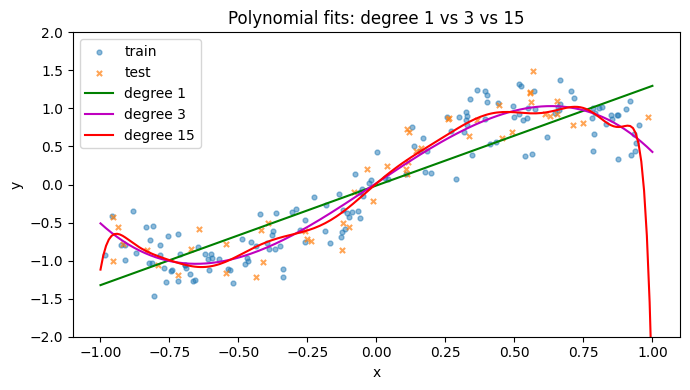

In [23]:
# does a curve fit better than a line? degrees 1 / 3 / 15
rng9 = np.random.default_rng(SEED)
x9 = rng9.uniform(-1, 1, 200)
y9 = np.sin(2.5 * x9) + np.random.default_rng(0).normal(0, 0.25, 200)
X9tr, X9te, y9tr, y9te = train_test_split(x9.reshape(-1, 1), y9,
                                          test_size=0.25, random_state=SEED)

def poly_pipe(degree):
    return Pipeline([("pf", PolynomialFeatures(degree=degree, include_bias=False)),
                     ("sc", StandardScaler()),
                     ("lr", LinearRegression())])

plt.figure(figsize=(7, 4))
plt.scatter(X9tr, y9tr, s=12, alpha=0.5, label="train")
plt.scatter(X9te, y9te, s=14, alpha=0.7, marker="x", label="test")
grid9 = np.linspace(-1, 1, 200).reshape(-1, 1)
for deg, style in zip((1, 3, 15), ("g-", "m-", "r-")):
    pipe_d = poly_pipe(deg).fit(X9tr, y9tr)
    print(f"degree {deg:>2}: train R² = {pipe_d.score(X9tr, y9tr):.4f}   "
          f"test R² = {pipe_d.score(X9te, y9te):.4f}")
    plt.plot(grid9, pipe_d.predict(grid9), style, lw=1.5, label=f"degree {deg}")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Polynomial fits: degree 1 vs 3 vs 15")
plt.legend(); plt.ylim(-2, 2); plt.tight_layout(); plt.show()
# NOTE: degree 1 underfits (a line cannot bend), degree 3 ≈ truth, degree 15
# memorises the training noise → train R² > test R² (OVERFITTING).


> **Gotcha:** high-degree polynomials are *ill-conditioned* — powers of $x$
> become wildly different in size, so `LinearRegression`/gradient descent
> struggle. **Always wrap `PolynomialFeatures` + `StandardScaler` +
> `LinearRegression` in a `Pipeline`** (and for degree ≥ ~10, prefer Ridge).

### `Pipeline(steps)`
**What it does:** chains transformers + a final estimator so that `fit` runs
every transformer *on training data only* and `predict` replays the same
transform — leak-proof by construction.
**Syntax:** `Pipeline([("pf", PolynomialFeatures(...)), ("sc", StandardScaler()), ("lr", LinearRegression())])`
**Parameters:** `steps` — list of `(name, estimator)` tuples; last step must
implement `fit`.
**Returns:** a single estimator with `.fit/.predict/.score/.fit_transform`.
**Example:**

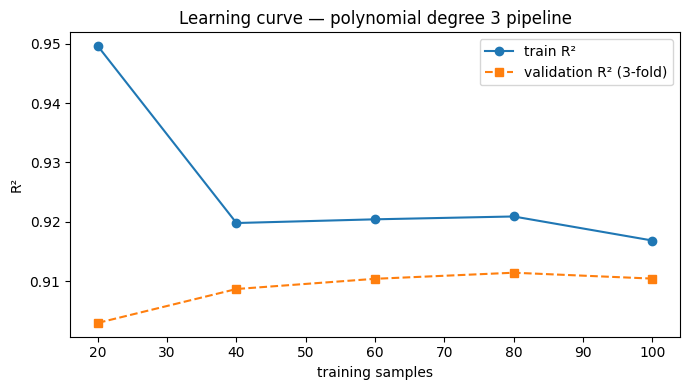

train R²: [0.95  0.92  0.92  0.921 0.917]
valid R²: [0.903 0.909 0.91  0.911 0.91 ]


In [24]:
# learning-curve-style demo: how does degree-3 model improve with more data?
pipe_lc = poly_pipe(3)
sizes, train_scores, val_scores = learning_curve(
    pipe_lc, X9tr, y9tr, train_sizes=np.linspace(0.2, 1.0, 5),
    cv=3, scoring="r2", random_state=SEED)

plt.figure(figsize=(7, 4))
plt.plot(sizes, train_scores.mean(axis=1), "o-", label="train R²")
plt.plot(sizes, val_scores.mean(axis=1), "s--", label="validation R² (3-fold)")
plt.xlabel("training samples"); plt.ylabel("R²")
plt.title("Learning curve — polynomial degree 3 pipeline")
plt.legend(); plt.tight_layout(); plt.show()
print("train R²:", np.round(train_scores.mean(axis=1), 3))
print("valid R²:", np.round(val_scores.mean(axis=1), 3))
# NOTE: parallel curves that both sit below target → underfitting (need more
# complexity); a wide gap → overfitting (need more data or regularization).


**Section notes — polynomial regression:**

| Item | Code |
|---|---|
| Build power columns | `PolynomialFeatures(degree=d, include_bias=False)` |
| Interactions only | `PolynomialFeatures(degree=2, interaction_only=True)` |
| Safe recipe | `Pipeline([("pf", ...), ("sc", StandardScaler()), ("lr", LinearRegression())])` |
| Complexity vs data | `learning_curve(pipe, X, y, cv=3, scoring="r2")` |
| Degree choice | lowest degree whose *validation* score plateaus |

---
## 10. Multicollinearity & the Variance Inflation Factor

▶ Session 53 – Multicollinearity: https://www.youtube.com/watch?v=XGJLWJ0a6aU

**Definition.** *Multicollinearity* = one or more features are well explained
by a **linear combination of the other features**. Perfect multicollinearity
makes $(X^\top X)^{-1}$ non-existent; *imperfect* multicollinearity still
exists and is the common case — it does not hurt prediction much, but it
**inflates coefficient variance**: standard errors blow up, signs flip, and
p-values become meaningless even though $R^2$ looks great.

**Variance Inflation Factor.** For feature $x_j$, regress it on *all other
features* and use that $R_j^2$:

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

| VIF | Interpretation |
|---|---|
| ≈ 1 | no correlation with the other features |
| < 5 | fine (rule of thumb: "acceptable") |
| 5–10 | moderate — investigate |
| > 10 | severe multicollinearity — act (drop / combine / PCA / regularise) |

**Condition number** $\kappa(X)=\sigma_{\max}/\sigma_{\min}$ is the sibling
diagnostic: $\kappa \gg 1000$ means near-linear-dependence (or features on
wildly different scales — always scale first before blaming the data).

### `vif(X, names)` — manual implementation (no extra dependency)
**What it does:** computes VIF for every column by looping the definition.
**Syntax:** `vif(X, names)`
**Parameters:** `X` — numeric matrix without target; `names` — column labels.
**Returns:** `pd.DataFrame` with $R^2$-vs-others and VIF per feature.
**Example:**

In [25]:
def vif_table(X, names):
    rows = {}
    for j in range(X.shape[1]):
        yj = X[:, j]
        others = np.delete(X, j, axis=1)          # every feature EXCEPT x_j
        r2 = LinearRegression().fit(others, yj).score(others, yj)
        rows[names[j]] = {"R2_vs_others": r2, "VIF": 1 / (1 - r2)}
    return pd.DataFrame(rows).T

rng10 = np.random.default_rng(SEED)
a = rng10.normal(0, 1, 200)
b = rng10.normal(0, 1, 200)
c = 3 * a - 2 * b + rng10.normal(0, 0.05, 200)   # ≈ perfect combo of a and b!
d = rng10.normal(0, 1, 200)                      # independent control
M = np.column_stack([a, b, c, d])
mnames = ["a", "b", "c = 3a − 2b", "d"]

print(vif_table(M, mnames).round(3))
print("condition number:", round(float(np.linalg.cond(M)), 1))

print("\nAfter dropping the redundant column c:")
print(vif_table(np.delete(M, 2, axis=1), ["a", "b", "d"]).round(3))
# NOTE: VIF(a) and VIF(b) are astronomical while c exists — the model can
# 'choose' any of the three interchangeable combinations; d (independent)
# stays at VIF ≈ 1 throughout.


             R2_vs_others       VIF
a                   1.000  2737.301
b                   0.999  1625.957
c = 3a − 2b         1.000  4658.494
d                   0.010     1.011
condition number: 264.7

After dropping the redundant column c:
   R2_vs_others    VIF
a         0.006  1.006
b         0.007  1.007
d         0.002  1.002


**Fixes for multicollinearity, in the order you should try them:**

| Fix | How | Trade-off |
|---|---|---|
| 1. Drop one of the pair | keep the feature with lower VIF / better domain meaning | lose information if both matter |
| 2. Combine features | ratios, sums, domain-engineered aggregates | needs domain knowledge |
| 3. PCA / dimensionality reduction | project to uncorrelated components | components lose interpretability |
| 4. Regularise (Ridge / ElasticNet) | penalty stabilises $\hat\beta$ even when $X^\top X$ is near-singular | coefficients biased toward 0 |
| 5. Collect more data | more rows shrink coefficient variance | often impossible |

> **Gotcha:** multicollinearity is about *inference instability*, not
> accuracy. A model with VIF = 50 can still predict perfectly well — the
> problem is that you cannot trust *which* feature is responsible, nor any
> p-value/t-statistic built on that coefficient.

**Section notes — multicollinearity:**

| Item | Formula / code |
|---|---|
| VIF | $\text{VIF}_j = 1/(1-R_j^2)$, $R_j^2$ from regressing $x_j$ on the rest |
| Thresholds | < 5 ok · 5–10 moderate · > 10 severe |
| Condition number | `np.linalg.cond(X)` (≫ 1000 is a red flag) |
| sklearn helper | `VarianceInflationFactor` from `statsmodels.stats.outliers_influence` |
| Fixes | drop · combine · PCA · Ridge/ElasticNet · more data |

---
## 11. Feature selection

▶ Session 54 – Feature Selection Part 1 | Filter Methods: https://www.youtube.com/watch?v=hRTe7tSkR2k
▶ Session 55 – Feature Selection Part 2 | Wrapper Methods: https://www.youtube.com/watch?v=6-1WiITAW10
▶ Session 3 on Feature Selection | Embedded Methods: https://www.youtube.com/watch?v=zLB-csjZ9V4

**Why bother?** Fewer features ⇒ **faster** training/scoring, **less
overfitting** (fewer chances to latch onto noise), **better interpretability**,
and lower data-collection cost. The three families:

| Family | How it scores features | Looks at the model? | Speed | Bias toward |
|---|---|---|---|---|
| **Filter** | statistical test / variance / correlation (model-free) | ❌ no | fastest | univariate relations only |
| **Wrapper** | trains models on feature *subsets* | ✅ yes | slowest (combinatorial) | the chosen model |
| **Embedded** | the estimator learns importances while fitting | ✅ during fit | fast | that estimator's inductive bias |

The demo data below has 11 columns: 4 genuinely informative
(`x2, x3, x6, x8`), 5 pure noise, one near-duplicate (`x0_dup`) and one
low-variance column (`low_var`) — so we *know* the right answer.

In [26]:
from sklearn.feature_selection import (VarianceThreshold, chi2, f_classif,
                                       f_regression, SelectKBest,
                                       SelectFromModel, RFE, RFECV)
from sklearn.ensemble import RandomForestRegressor

rng11 = np.random.default_rng(SEED)
base11, y11, coef11 = make_regression(n_samples=250, n_features=9, n_informative=4,
                                      noise=10, random_state=SEED, coef=True)
dup11 = base11[:, 0] + rng11.normal(0, 0.01, 250)   # near-copy of x0 (r ≈ 1)
lowvar11 = np.abs(rng11.normal(0, 1, 250))          # low-variance feature
X11 = np.hstack([base11, dup11[:, None], lowvar11[:, None]])
fn11 = np.array([f"x{i}" for i in range(9)] + ["x0_dup", "low_var"])

info11 = np.where(np.abs(coef11) > 1)[0]
print("features :", list(fn11))
print("informative:", list(fn11[info11]), "| noise:", list(fn11[np.where(np.abs(coef11) <= 1)[0]]))
print("variance of low_var:", round(float(lowvar11.var()), 3),
      "| others ~", np.round(X11.var(axis=0)[:3], 2))


features : [np.str_('x0'), np.str_('x1'), np.str_('x2'), np.str_('x3'), np.str_('x4'), np.str_('x5'), np.str_('x6'), np.str_('x7'), np.str_('x8'), np.str_('x0_dup'), np.str_('low_var')]
informative: [np.str_('x2'), np.str_('x3'), np.str_('x6'), np.str_('x8')] | noise: [np.str_('x0'), np.str_('x1'), np.str_('x4'), np.str_('x5'), np.str_('x7')]
variance of low_var: 0.356 | others ~ [1.09 0.86 0.92]


### FILTER 1 — variance threshold
### `VarianceThreshold(threshold=0.0)`
**What it does:** drops columns whose variance is ≤ `threshold` (zero-variance
features are useless; near-zero ones are often noise).
**Parameters:** `threshold` — float — minimum variance to **keep** (default 0.0).
**Returns:** `.fit(X)` stores `.variances_`; `.get_support()` = boolean mask,
`.transform(X)` = the reduced matrix.
**Example:**

In [27]:
vt = VarianceThreshold(threshold=0.5).fit(X11)
print("variances :", np.round(vt.variances_, 3))
print("kept      :", fn11[vt.get_support()])
print("dropped   :", fn11[~vt.get_support()])


variances : [1.089 0.862 0.925 1.071 0.929 0.904 0.904 1.042 1.024 1.088 0.356]
kept      : ['x0' 'x1' 'x2' 'x3' 'x4' 'x5' 'x6' 'x7' 'x8' 'x0_dup']
dropped   : ['low_var']


### FILTER 2 — correlation-based removal
Drop one feature of any pair with $|r| > 0.9$ — a near-perfect duplicate adds
no information (and inflates VIF, §10). *(Bivariate filter: fast, but it
never sees the target.)*

In [28]:
corr11 = np.corrcoef(X11, rowvar=False)
to_drop = set()
for i in range(X11.shape[1]):
    for j in range(i + 1, X11.shape[1]):
        if abs(corr11[i, j]) > 0.9 and j not in to_drop:
            print(f"drop {fn11[j]} — cor({fn11[i]}, {fn11[j]}) = {corr11[i, j]:.4f}")
            to_drop.add(j)
kept11 = [k for k in range(X11.shape[1]) if k not in to_drop]
print("remaining features:", len(kept11), "→", fn11[kept11])


drop x0_dup — cor(x0, x0_dup) = 1.0000
remaining features: 10 → ['x0' 'x1' 'x2' 'x3' 'x4' 'x5' 'x6' 'x7' 'x8' 'low_var']


### FILTER 3 — statistical tests with `SelectKBest`
### `SelectKBest(score_func, k=10)`
**What it does:** scores every feature with `score_func(X, y)` and keeps the
top `k`.
**Parameters:**
- `score_func` — callable `(X, y) → (scores, p_values)` — e.g. `chi2`,
  `f_classif` (classification), `f_regression` (regression)
- `k` — int or `"all"` — number of features to keep
**Returns:** `.get_support()` mask, `.transform(X)`, `.scores_`, `.pvalues_`.
**Example:**

In [29]:
yc11 = (y11 > np.median(y11)).astype(int)        # binarise target for the class tests

chi_scores, chi_p = chi2(np.abs(X11), yc11)      # chi² needs NON-NEGATIVE inputs
f_cls_scores, f_cls_p = f_classif(X11, yc11)     # ANOVA F-test (classification)
fr_scores, fr_p = f_regression(X11, y11)         # F-test (regression)

score_tbl = pd.DataFrame({"chi2": chi_scores, "f_classif": f_cls_scores,
                          "f_regression": fr_scores}, index=fn11)
print(score_tbl.round(2))

kbest = SelectKBest(f_regression, k=4).fit(X11, y11)
print("\nf_regression top-4:", fn11[kbest.get_support()], "→ matches the truth")
# NOTE: chi² is designed for counts/frequencies — on continuous (possibly
# negative) features its ranking is unreliable. It is a classification filter
# for non-negative inputs such as word counts or pixel values.


         chi2  f_classif  f_regression
x0       0.65       0.12          0.33
x1       0.21       0.18          0.19
x2       0.00       6.22         12.81
x3       0.66      34.53         75.25
x4       0.69       0.02          0.66
x5       0.10       1.69          0.62
x6       1.72     113.68        186.34
x7       0.75       0.06          0.00
x8       0.00      37.63         68.82
x0_dup   0.66       0.13          0.33
low_var  0.11       0.23          0.50

f_regression top-4: ['x2' 'x3' 'x6' 'x8'] → matches the truth


### WRAPPER 1 — forward selection
Start empty; at every step add the candidate whose addition gives the biggest
jump in **adjusted** $R^2$; stop when nothing helps (or `max_features` hit).
Cost: $\mathcal O(p^2)$ model fits — exact but slow for large $p$.

In [30]:
def adj_r2(r2, n, k):
    """Adjusted R² — penalises each added feature."""
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)

def forward_selection(X, y, names, max_features=6):
    n = X.shape[0]
    selected, best_adj = [], -np.inf
    for _ in range(max_features):
        best_j, best_v = None, best_adj
        for j in range(X.shape[1]):
            if j in selected:
                continue
            cand = selected + [j]
            r2 = LinearRegression().fit(X[:, cand], y).score(X[:, cand], y)
            v = adj_r2(r2, n, len(cand))
            if v > best_v + 1e-9:
                best_j, best_v = j, v
        if best_j is None:                    # no improvement → stop
            break
        selected.append(best_j)
        best_adj = best_v
        print(f"  step {len(selected)}: add {fn11[best_j]:>7}  adj R² = {best_adj:.4f}")
    return selected

print("Forward selection:")
sel_fwd = forward_selection(X11, y11, fn11)


Forward selection:
  step 1: add      x6  adj R² = 0.4267
  step 2: add      x3  adj R² = 0.7186
  step 3: add      x8  adj R² = 0.9522
  step 4: add      x2  adj R² = 0.9917


### WRAPPER 2 — backward elimination
Start with **all** features; repeatedly remove the one whose removal *raises*
(or least hurts) adjusted $R^2$; stop when removal no longer helps.

In [31]:
def backward_elimination(X, y, names):
    n, p = X.shape
    selected = list(range(p))
    while len(selected) > 1:
        r2 = LinearRegression().fit(X[:, selected], y).score(X[:, selected], y)
        full_adj = adj_r2(r2, n, len(selected))
        worst_j, worst_v = None, -np.inf
        for j in selected:
            rest = [k for k in selected if k != j]
            r2c = LinearRegression().fit(X[:, rest], y).score(X[:, rest], y)
            v = adj_r2(r2c, n, len(rest))
            if v > worst_v:
                worst_v, worst_j = v, j
        if worst_v >= full_adj - 1e-9:        # dropping improves adj R² → drop it
            selected.remove(worst_j)
            print(f"  drop {names[worst_j]:>7}  adj R² = {worst_v:.4f} "
                  f"(was {full_adj:.4f}, {len(selected)} left)")
        else:
            break
    return selected

print("Backward elimination:")
sel_bwd = backward_elimination(X11, y11, fn11)


Backward elimination:
  drop      x5  adj R² = 0.9916 (was 0.9915, 10 left)
  drop      x4  adj R² = 0.9916 (was 0.9916, 9 left)
  drop  x0_dup  adj R² = 0.9916 (was 0.9916, 8 left)
  drop      x0  adj R² = 0.9917 (was 0.9916, 7 left)
  drop      x7  adj R² = 0.9917 (was 0.9917, 6 left)
  drop      x1  adj R² = 0.9917 (was 0.9917, 5 left)
  drop low_var  adj R² = 0.9917 (was 0.9917, 4 left)


### WRAPPER 3 — `RFE` / `RFECV`
### `RFE(estimator, n_features_to_select=None, step=1)`
**What it does:** repeatedly fits `estimator`, drops the **least important
feature** (by `coef_` or `feature_importances_`), and repeats until
`n_features_to_select` remain — recursive *backward* elimination driven by a
model instead of by $R^2$.
**Parameters:**
- `estimator` — object with `fit` + (`coef_` or `feature_importances_`)
- `n_features_to_select` — int — how many to keep
- `step` — int/float — features removed per iteration
**Returns:** `.support_` mask, `.ranking_` (1 = selected), `.transform(X)`.

### `RFECV(estimator, cv=None, scoring=None, min_features_to_select=1)`
**What it does:** RFE **plus** cross-validation — chooses the number of
features that gives the best CV score (the honest version of RFE).
**Parameters:** `cv` — folds; `scoring` — metric; `min_features_to_select`.
**Returns:** same as RFE + `.cv_results_`, `.n_features_`.
**Example:**

In [32]:
rfe = RFE(LinearRegression(), n_features_to_select=4, step=1).fit(X11, y11)
print("RFE (keep 4)     :", fn11[rfe.support_], "| ranking:", rfe.ranking_)

rfecv = RFECV(LinearRegression(), min_features_to_select=1, cv=3,
              scoring="r2").fit(X11, y11)
print("RFECV best count :", rfecv.n_features_, "→", fn11[rfecv.support_])
# NOTE: RFE ranks by |coef_| on the UNSCALED X11, so the redundant pair
# x0 / x0_dup sneaks in — standardise first (or trust RFECV's cross-validated
# feature COUNT more than any single ranking) before acting on the result.


RFE (keep 4)     : ['x0' 'x3' 'x6' 'x0_dup'] | ranking: [1 6 3 1 7 8 1 5 2 1 4]
RFECV best count : 6 → ['x0' 'x2' 'x3' 'x6' 'x8' 'x0_dup']


### EMBEDDED 1 — L1 regularization (`select_from_model`)
Lasso shrinks noise coefficients **exactly to zero** while fitting (§14), so
feature selection falls out of training for free.

### EMBEDDED 2 — tree importances (`feature_importances_`)
Random forests measure how much each split reduces impurity, averaged over
all trees — model-native, non-linear aware, but biased toward high-cardinality
columns.

Lasso select_from_model: ['x2' 'x3' 'x6' 'x8']



RandomForest importances:
 x0_dup     0.0068
x0         0.0069
x1         0.0087
x4         0.0097
x5         0.0111
x7         0.0137
low_var    0.0147
x2         0.0238
x8         0.1620
x3         0.2594
x6         0.4830
dtype: float64


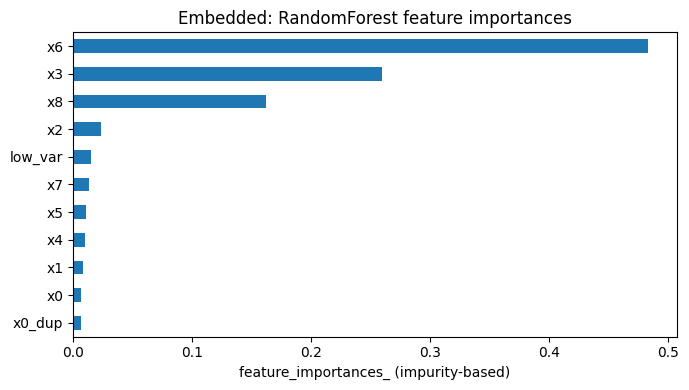

In [33]:
sfm = SelectFromModel(Lasso(alpha=0.5, max_iter=20000, random_state=SEED)).fit(X11, y11)
print("Lasso select_from_model:", fn11[sfm.get_support()])

rf11 = RandomForestRegressor(n_estimators=200, random_state=SEED).fit(X11, y11)
imp11 = pd.Series(rf11.feature_importances_, index=fn11).sort_values()
print("\nRandomForest importances:\n", imp11.round(4))

plt.figure(figsize=(7, 4))
imp11.plot(kind="barh")
plt.xlabel("feature_importances_ (impurity-based)")
plt.title("Embedded: RandomForest feature importances")
plt.tight_layout(); plt.show()


> **Gotcha — selection leakage:** every selector above must be **fit on the
> training split only**, then applied to the test split
> (`selector.fit_transform(X_train)` / `selector.transform(X_test)`). If you
> run `SelectKBest` on the full dataset first, the *test* labels influenced
> which features survived → your test score is quietly optimistic. The
> leak-proof pattern is `Pipeline([("sel", SelectKBest(...)), ("lr", LinearRegression())])`.

**Section notes — feature selection:**

| Family | Tools in sklearn | Best for |
|---|---|---|
| Filter | `VarianceThreshold`, `SelectKBest(chi2/f_classif/f_regression)`, correlation matrix | quick pre-filter, $p$ huge, model-agnostic |
| Wrapper | forward/backward loops, `RFE`, `RFECV` | small $p$, accuracy matters most |
| Embedded | `SelectFromModel(Lasso)`, `RandomForest.feature_importances_`, tree `coef_` | speed + model-aware ranking |

| Comparison | Filter | Wrapper | Embedded |
|---|---|---|---|
| Time | ⚡ fastest | 🐢 slowest | ⚡ fast |
| Accuracy | weakest (univariate) | strongest (uses the model) | strong |
| Model dependency | none | total | partial |
| Typical use | drop 90 % of junk columns first | final polish on ≤ 50 features | default in pipelines |

---
## 12. Regularization theory — bias, variance, and the penalty idea

▶ Regularization Part 1 | Bias Variance Trade-off: https://www.youtube.com/watch?v=qfWUIUvKi98
▶ Regularization Part 2 | What is Regularization?: https://www.youtube.com/watch?v=cVsN5VAioz0
▶ Doubt Clearance Session on Regularization: https://www.youtube.com/watch?v=7_DDQkLzmRM

**Underfitting vs overfitting** are the two ways a model fails:

| | Underfit (high bias) | Just right | Overfit (high variance) |
|---|---|---|---|
| Train error | high | low | very low |
| Test error | high | low | high (gap vs train) |
| Model too… | simple (degree 1) | matched to data | complex (degree 15) |
| Fix | add features/complexity | — | more data, drop features, regularise |

**Bias–variance decomposition.** For squared error the expected error on a
*new* point splits into three parts:

$$\mathbb E\big[(y - \hat f(x))^2\big] \;=\;
\underbrace{\big(\mathbb E[\hat f(x)] - f(x)\big)^2}_{\text{bias}^2}
\;+\; \underbrace{\mathbb E\big[(\hat f(x) - \mathbb E[\hat f(x)])^2\big]}_{\text{variance}}
\;+\; \underbrace{\sigma^2}_{\text{irreducible noise}}$$

- **Bias** — systematic error from wrong assumptions (a straight line on
    curved data). ↓ as model complexity ↑.
- **Variance** — sensitivity to the particular training sample. ↑ as
    complexity ↑ (and as $n$ ↓).
- **Noise** — floor you can never beat; the gap between "perfect model" and
    perfect predictions.

**Total error = bias² + variance + noise** ⇒ pick the complexity where the
*sum* is minimised (the validation curve below has its minimum there).

**The regularization idea.** Add a **penalty on model size** to the cost:

$$J_{\text{reg}}(\beta) \;=\; \underbrace{\text{MSE}(\beta)}_{\text{fit the data}}
\;+\; \underbrace{\lambda\,\Omega(\beta)}_{\text{keep the model small}}$$

This deliberately *worsens* training fit to lower variance — trading a little
bias for a much bigger drop in variance (§13 Ridge: $\Omega=\sum\beta_j^2$,
§14 Lasso: $\Omega=\sum|\beta_j|$). **Why coefficients shrink:** any
non-zero $\beta$ now costs part of the objective, so the optimiser only
keeps coefficients that genuinely buy enough error reduction to pay for their
own size. Oversized coefficients that were fitting *noise* cannot pay, and
get pushed toward 0.

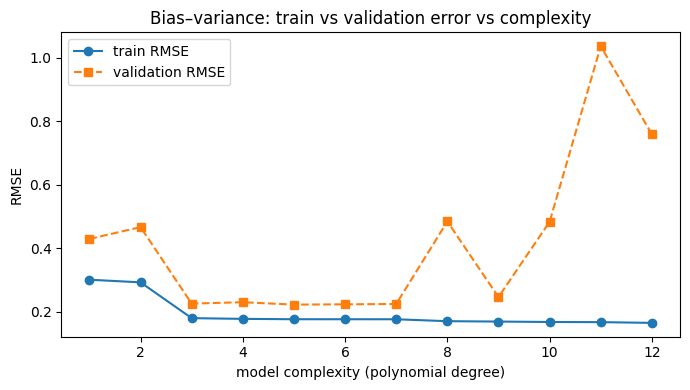

train RMSE: [0.3   0.292 0.179 0.177 0.176 0.176 0.176 0.17  0.169 0.167 0.167 0.164]
valid RMSE: [0.429 0.466 0.225 0.23  0.222 0.223 0.224 0.484 0.246 0.483 1.036 0.758]
best validation degree = 5 (left of it: underfitting · right of it: overfitting)


In [34]:
# complexity curve: train vs validation error as the model gets more complex
rng12 = np.random.default_rng(SEED)
x12 = rng12.uniform(-1, 1, 80)
y12 = np.sin(2.5 * x12) + np.random.default_rng(0).normal(0, 0.2, 80)
X12tr, X12te, y12tr, y12te = train_test_split(x12.reshape(-1, 1), y12,
                                              test_size=0.3, random_state=SEED)

train_rmse, test_rmse = [], []
for d in range(1, 13):
    p_d = poly_pipe(d).fit(X12tr, y12tr)          # pipeline from §9
    train_rmse.append(np.sqrt(mean_squared_error(y12tr, p_d.predict(X12tr))))
    test_rmse.append(np.sqrt(mean_squared_error(y12te, p_d.predict(X12te))))

plt.figure(figsize=(7, 4))
plt.plot(range(1, 13), train_rmse, "o-", label="train RMSE")
plt.plot(range(1, 13), test_rmse, "s--", label="validation RMSE")
plt.xlabel("model complexity (polynomial degree)"); plt.ylabel("RMSE")
plt.title("Bias–variance: train vs validation error vs complexity")
plt.legend(); plt.tight_layout(); plt.show()
best_deg = int(np.argmin(test_rmse)) + 1
print(f"train RMSE: {np.round(train_rmse, 3)}")
print(f"valid RMSE: {np.round(test_rmse, 3)}")
print(f"best validation degree = {best_deg} "
      f"(left of it: underfitting · right of it: overfitting)")


**Section notes — bias/variance & regularization:**

| Item | Formula / idea |
|---|---|
| Total error | $\text{bias}^2 + \text{variance} + \sigma^2$ |
| Complexity ↑ | bias ↓, variance ↑ |
| Regularized cost | $\text{MSE} + \lambda\,\Omega(\beta)$ |
| Effect | coefficients shrink → variance ↓ (bias ↑ slightly) |
| Diagnosis | train/val curves: gap ⇒ overfit, both high ⇒ underfit |

> **Gotcha:** $R^2$ on the *training* set can always be improved by adding
> features — that is why model selection must happen on validation data (or
> CV), never on training scores.

---
## 13. Ridge regression (L2)

▶ Ridge Regression Part 1 (Geometric Intuition): https://www.youtube.com/watch?v=aEow1QoTLo0
▶ Ridge Regression Part 2 (Math + code from scratch): https://www.youtube.com/watch?v=oDlZBQjk_3A
▶ Ridge Regression Part 3 (Gradient Descent): https://www.youtube.com/watch?v=Fci_wwMp8G8
▶ 5 Key Points - Ridge Regression Part 4: https://www.youtube.com/watch?v=8osKeShYVRQ

**Cost function:**

$$J_{\text{Ridge}}(\beta) \;=\; \underbrace{\frac1n\sum_i (y_i - \hat y_i)^2}_{\text{MSE}}
\;+\; \alpha\sum_{j=1}^{p}\beta_j^2$$

**Closed form** (differentiate, set to 0 — note the intercept is *not*
penalised):

$$\hat\beta = \left(X^\top X + \alpha I\right)^{-1} X^\top Y$$

The $\alpha I$ term is the trick: even when $X^\top X$ is singular (perfect
multicollinearity, $p > n$), adding $\alpha I$ makes it invertible — Ridge
*always* has a unique solution.

**Geometric intuition (why the circles vs contours matter).** The loss
$\text{MSE}(\beta)$ is an elliptical contour bowl around the OLS solution; the
constraint region $\sum\beta_j^2 \le t$ (the budget that $\alpha$ controls) is
a **circle/sphere**. The optimum sits where a contour first touches the circle
— generically at a point where *all* coordinates are non-zero ⇒ Ridge shrinks
but **rarely zeroes** a coefficient. (§14: Lasso's region is a **diamond**,
whose corners lie *on the axes* — that is where zeros come from.)

### `Ridge(alpha=1.0, *, fit_intercept=True, copy_X=True, tol=1e-4, solver='auto', random_state=None)`
**What it does:** linear regression with an L2 penalty on the coefficients.
**Syntax:** `Ridge(alpha=1.0).fit(X, y)`
**Parameters:**
- `alpha` — float — penalty strength $\alpha$ (default `1.0`; `0` = plain OLS)
- `fit_intercept` — bool — fit an unpenalised intercept (default `True`)
- `solver` — `'auto'`/`'svd'`/`'cholesky'`/`'lsqr'`/`'sparse_cg'`/`'sgd'` — how
  the system is solved (default `'auto'` picks by shape/density)
- `tol` — float — solver convergence tolerance
**Returns:** fitted estimator with `.coef_`, `.intercept_`.
**Example:** below.

scratch GD : [ 6.2800e-01 -6.1600e-01  7.3020e+00  1.6591e+01  1.2820e+00  1.1690e+00
  2.3008e+01  2.3000e-02  1.6037e+01  6.2500e-01  1.1120e+00]
sklearn    : [ 6.2800e-01 -6.1600e-01  7.3020e+00  1.6591e+01  1.2820e+00  1.1690e+00
  2.3008e+01  2.3000e-02  1.6037e+01  6.2500e-01  1.1120e+00]
max |diff| = 0.000000  (both solve the same normal equations)
cost: 10531.8 → 7104.6


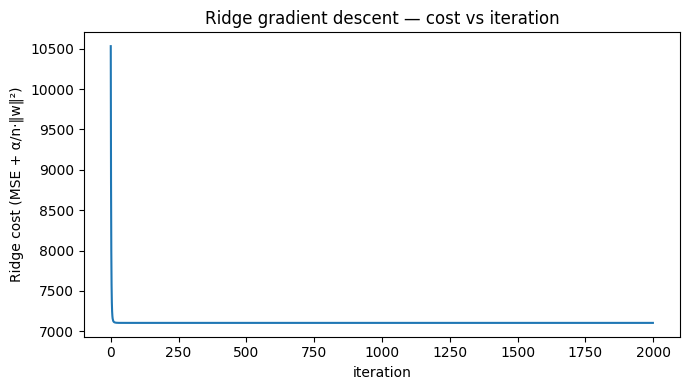

In [35]:
X13 = StandardScaler().fit_transform(X11)   # reuse §11 features — scaled (§4!)
y13 = y11

def ridge_gd(X, y, alpha, lr=0.05, n_iter=2000):
    """Batch gradient descent on the Ridge cost (intercept unpenalised)."""
    n, p = X.shape
    w = np.zeros(p)
    b = 0.0
    costs = []
    for _ in range(n_iter):
        err = y - (b + X @ w)
        costs.append(np.mean(err ** 2) + (alpha / n) * np.sum(w ** 2))
        b -= lr * (-2 / n) * err.sum()                                   # data gradient
        w -= lr * ((-2 / n) * (X.T @ err) + (2 * alpha / n) * w)         # data + L2
    return b, w, costs

b_r, w_r, costs_r = ridge_gd(X13, y13, alpha=500)
sk_r = Ridge(alpha=500).fit(X13, y13)

print("scratch GD :", np.round(w_r, 3))
print("sklearn    :", np.round(sk_r.coef_, 3))
print(f"max |diff| = {np.max(np.abs(w_r - sk_r.coef_)):.6f}  "
      f"(both solve the same normal equations)")
print(f"cost: {costs_r[0]:.1f} → {costs_r[-1]:.1f}")

plt.figure(figsize=(7, 4))
plt.plot(costs_r)
plt.xlabel("iteration"); plt.ylabel("Ridge cost (MSE + α/n·‖w‖²)")
plt.title("Ridge gradient descent — cost vs iteration")
plt.tight_layout(); plt.show()


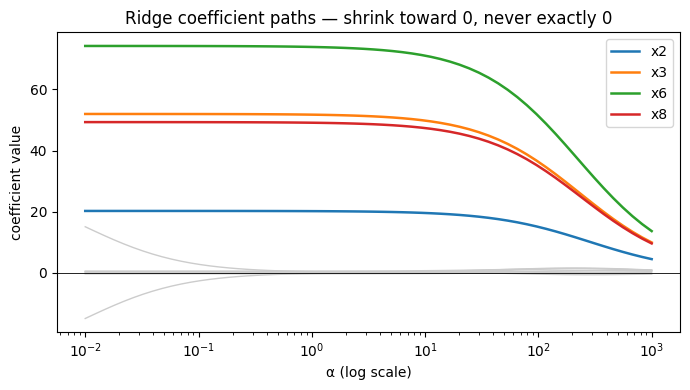

α → 0   : max |coef| = 74.26  (≈ OLS)
α = 10  : max |coef| = 71.08
α → ∞   : max |coef| = 13.62  (shrinking toward 0)


In [36]:
# effect of α on the coefficients — coefficient paths
alphas13 = np.logspace(-2, 3, 60)
paths13 = np.array([Ridge(alpha=a).fit(X13, y13).coef_ for a in alphas13])

info11 = np.where(np.abs(coef11) > 1)[0]
plt.figure(figsize=(7, 4))
for j in range(paths13.shape[1]):
    if j in info11:
        plt.plot(alphas13, paths13[:, j], lw=1.8, label=fn11[j])
    else:
        plt.plot(alphas13, paths13[:, j], color="0.8", lw=1)   # noise features
plt.xscale("log")
plt.axhline(0, color="k", lw=0.6)
plt.xlabel("α (log scale)"); plt.ylabel("coefficient value")
plt.title("Ridge coefficient paths — shrink toward 0, never exactly 0")
plt.legend(loc="best"); plt.tight_layout(); plt.show()

print(f"α → 0   : max |coef| = {np.max(np.abs(paths13[0])):.2f}  (≈ OLS)")
print(f"α = 10  : max |coef| = {np.max(np.abs(Ridge(alpha=10).fit(X13, y13).coef_)):.2f}")
print(f"α → ∞   : max |coef| = {np.max(np.abs(paths13[-1])):.2f}  (shrinking toward 0)")


In [37]:
# scale invariance check: the SAME α gives different fits on unscaled features
r_raw = Ridge(alpha=10).fit(X11, y11).coef_
r_scaled = Ridge(alpha=10).fit(X13, y11).coef_
print("α=10 on raw features    :", np.round(r_raw, 2))
print("α=10 on scaled features :", np.round(r_scaled, 2))
print("→ the penalty treats a unit of every feature alike, so FEATURE SCALE",
      "decides how hard it is shrunk. Always StandardScaler() first.")


α=10 on raw features    : [ 1.200e-01  2.200e-01  2.025e+01  4.823e+01  4.500e-01  1.100e-01
  7.446e+01 -2.600e-01  4.684e+01  5.000e-02  1.010e+00]
α=10 on scaled features : [ 1.200e-01  2.100e-01  1.955e+01  4.981e+01  4.200e-01  9.000e-02
  7.108e+01 -2.800e-01  4.736e+01  6.000e-02  6.600e-01]
→ the penalty treats a unit of every feature alike, so FEATURE SCALE decides how hard it is shrunk. Always StandardScaler() first.


### 5 key points — Ridge recap (session #172)

1. **Ridge shrinks coefficients toward zero but almost never to exactly zero**
   → it *cannot* do feature selection (the circle touches contours at
   off-axis points).
2. **It reduces variance at the price of a little bias** — test error improves
   when features are many and collinear; training $R^2$ always drops slightly.
3. **$\alpha$ is the dial:** $\alpha \to 0$ recovers OLS, $\alpha \to \infty$
   forces every $\beta_j \to 0$ (prediction = intercept). Choose it with CV.
4. **Standardise first** — the penalty is scale-dependent, so a feature with
   large units is penalised less per unit and dominates the fit.
5. **Closed form exists** — $\hat\beta=(X^\top X+\alpha I)^{-1}X^\top Y$ — and
   $\alpha I$ guarantees invertibility ⇒ Ridge is the safe default when
   multicollinearity or $p \gtrsim n$ breaks OLS.

**Section notes — Ridge:**

| Item | Code / formula |
|---|---|
| Cost | $\text{MSE} + \alpha\sum\beta_j^2$ |
| Closed form | $(X^\top X+\alpha I)^{-1}X^\top Y$ |
| sklearn | `Ridge(alpha=...)` |
| From scratch | gradient of MSE + `2αβ/n` term on $w$ (not on $b$) |
| Paths | `np.logspace(-2, 3, 60)` alphas → `.coef_` per alpha |
| Hyper-parameter | `GridSearchCV(Ridge(), {"alpha": ...})` |

---
## 14. Lasso regression (L1)

▶ Lasso Regression: https://www.youtube.com/watch?v=HLF4bFbBgwk
▶ Why Lasso creates sparsity: https://www.youtube.com/watch?v=FN4aZPIAfI4

**Cost function:**

$$J_{\text{Lasso}}(\beta) \;=\; \frac1n\sum_i (y_i - \hat y_i)^2
\;+\; \alpha\sum_{j=1}^{p}|\beta_j|$$

**Subgradient note.** $|\beta|$ is not differentiable at 0, so we use the
*subgradient*: $\partial|\beta| = \operatorname{sign}(\beta)$ for
$\beta \neq 0$, and any value in $[-1, 1]$ at $\beta = 0$. The optimality
condition at a zero coefficient is
$\big|\tfrac1n x_j^\top (y - X\hat\beta)\big| \le \alpha$ — once the
correlation of feature $j$ with the residual is below $\alpha$, the optimum
sits *exactly* at the kink and the coefficient stays 0. (sklearn's coordinate
descent sets small coefficients to 0 precisely via this rule.)

**Why the diamond ⇒ zeros (geometry).** Lasso's constraint region
$\sum|\beta_j| \le t$ is a **diamond (rotated square)** whose corners lie
**on the axes**. The elliptical loss contours sliding outward hit a *corner*
far more often than a flat edge — and a corner means every other coordinate
is exactly 0. Ridge's circle has no corners ⇒ no zeros. This single geometric
fact is the whole answer to *"why does Lasso create sparsity?"*.

### `Lasso(alpha=1.0, *, fit_intercept=True, max_iter=1000, tol=1e-4, selection='cyclic', random_state=None)`
**What it does:** linear regression with an L1 penalty → sparse solutions.
**Syntax:** `Lasso(alpha=1.0).fit(X, y)`
**Parameters:**
- `alpha` — float — penalty strength (default `1.0`; `0` = OLS)
- `max_iter` — int — coordinate-descent iterations (raise it if you see
  `ConvergenceWarning`)
- `tol` — float — stopping tolerance on the coordinate updates
- `selection` — `'cyclic'`/`'random'` — update order (`'random'` uses `random_state`)
**Returns:** fitted estimator with `.coef_`, `.intercept_` (zeros included).
**Example:**

In [38]:
las14 = Lasso(alpha=1.0, max_iter=20000, random_state=SEED).fit(X13, y13)
rid14 = Ridge(alpha=1.0).fit(X13, y13)
coef_tbl = pd.DataFrame({"Lasso(alpha=1.0)": las14.coef_,
                         "Ridge(alpha=1.0)": rid14.coef_}, index=fn11)
print(coef_tbl.round(3))
print("\nexact zeros — Lasso:", int((las14.coef_ == 0).sum()),
      "| Ridge:", int((rid14.coef_ == 0).sum()))
print("Lasso kept (non-zero):", fn11[las14.coef_ != 0],
      " ← exactly the 4 informative features")
# NOTE: Lasso has effectively done FEATURE SELECTION while fitting.


         Lasso(alpha=1.0)  Ridge(alpha=1.0)
x0                 -0.000             0.329
x1                  0.000             0.357
x2                 19.342            20.156
x3                 50.963            51.756
x4                  0.000             0.209
x5                 -0.000            -0.121
x6                 73.037            73.932
x7                 -0.000            -0.355
x8                 48.420            49.115
x0_dup             -0.000            -0.272
low_var             0.000             0.528

exact zeros — Lasso: 7 | Ridge: 0
Lasso kept (non-zero): ['x2' 'x3' 'x6' 'x8']  ← exactly the 4 informative features


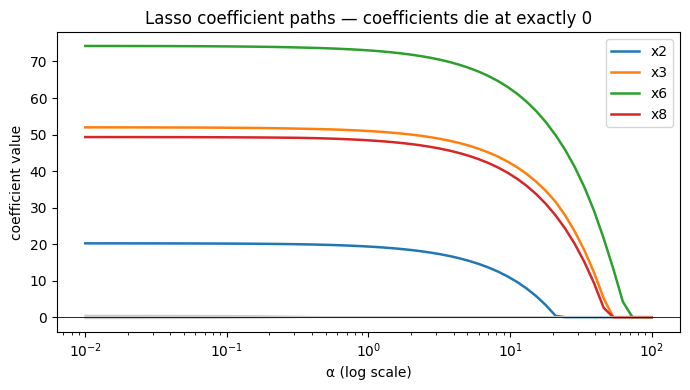

α = 0.01 : zeros =  1/11
α = 0.1  : zeros =  2/11
α = 0.5  : zeros =  6/11
α = 1.0  : zeros =  7/11


In [39]:
# Lasso coefficient paths — watch features snap to exactly zero
alphas14 = np.logspace(-2, 2, 60)
paths14 = np.array([Lasso(alpha=a, max_iter=20000, random_state=SEED)
                    .fit(X13, y13).coef_ for a in alphas14])

plt.figure(figsize=(7, 4))
for j in range(paths14.shape[1]):
    if j in info11:
        plt.plot(alphas14, paths14[:, j], lw=1.8, label=fn11[j])
    else:
        plt.plot(alphas14, paths14[:, j], color="0.8", lw=1)
plt.xscale("log")
plt.axhline(0, color="k", lw=0.6)
plt.xlabel("α (log scale)"); plt.ylabel("coefficient value")
plt.title("Lasso coefficient paths — coefficients die at exactly 0")
plt.legend(loc="best"); plt.tight_layout(); plt.show()
for probe in (0.01, 0.1, 0.5, 1.0):
    c_p = Lasso(alpha=probe, max_iter=20000).fit(X13, y13).coef_
    print(f"α = {probe:<5}: zeros = {int((c_p == 0).sum()):>2}/11")


In [40]:
# Lasso with (near) correlated features: it must choose ONE of the pair
rng14 = np.random.default_rng(SEED)
xr1 = rng14.normal(0, 1, 200)
xr2 = xr1 + rng14.normal(0, 0.05, 200)          # xr2 ≈ xr1 (r ≈ 0.999)
yr14 = 5 * xr1 + rng14.normal(0, 1, 200)
X14c = np.column_stack([xr1, xr2])

print("model                           coef(xr1)  coef(xr2)")
print("OLS (splits arbitrarily)      ", np.round(LinearRegression().fit(X14c, yr14).coef_, 2))
print("Ridge (shares the weight)     ", np.round(Ridge(alpha=1.0).fit(X14c, yr14).coef_, 2))
print("Lasso (picks one, drops one)  ", np.round(Lasso(alpha=0.5, max_iter=20000).fit(X14c, yr14).coef_, 2))
# NOTE: OLS splits the twin signal 4.33 / 0.62 — that split swings wildly
# across samples; Ridge divides it more evenly (2.85 / 2.08); Lasso sets one
# column to EXACTLY 0 — and which twin survives can flip with tiny data
# changes → unstable interpretation with correlated features.


model                           coef(xr1)  coef(xr2)
OLS (splits arbitrarily)       [4.33 0.62]
Ridge (shares the weight)      [2.85 2.08]
Lasso (picks one, drops one)   [4.3 0. ]


**When Lasso fails (or misleads):**

- **Correlated feature groups** — it keeps an arbitrary member and zeroes the
  rest (see the demo above); coefficient *magnitude* of the survivors is also
  biased downward.
- **$p \gg n$ with > $n$ active signals** — Lasso can select at most $n$
  features; beyond that it silently drops real ones.
- **Stability** — small changes in data can flip which correlated column
  survives; use ElasticNet (§15) or stability selection instead.

> **Gotcha:** `Lasso(alpha=0)` is *not* OLS — it falls back on a pseudo-inverse
> path and can warn; use `LinearRegression()` for OLS. And a huge `alpha`
> zeroes *everything*, giving the intercept-only baseline.

**Section notes — Lasso:**

| Item | Code / formula |
|---|---|
| Cost | $\text{MSE} + \alpha\sum\lvert\beta_j\rvert$ |
| Optimality at 0 | $\lvert x_j^\top\varepsilon\rvert/n \le \alpha$ (subgradient) |
| sklearn | `Lasso(alpha=...)` — bump `max_iter` on warnings |
| Geometry | diamond constraint → corner solutions → exact zeros |
| Bonus | doubles as a feature selector (`SelectFromModel`) |
| Weakness | correlated features → arbitrary pick |

---
## 15. ElasticNet regression (L1 + L2)

▶ ElasticNet Regression: https://www.youtube.com/watch?v=2g2DBkFhTTY

**Cost function:**

$$J_{\text{EN}}(\beta) \;=\; \frac1n\sum_i (y_i - \hat y_i)^2
\;+\; \alpha\Big(\rho\sum_j|\beta_j| \;+\; (1-\rho)\sum_j\beta_j^2\Big)$$

where `l1_ratio` $=\rho$ interpolates between the two worlds
($\rho=1$ → pure Lasso, $\rho=0$ → pure Ridge).

**sklearn's exact objective** (so your $\alpha$ means the same thing in code):
$\frac{1}{2n}\|y-Xw\|^2 + \alpha\,\rho\|w\|_1 + \tfrac12\alpha(1-\rho)\|w\|_2^2$

### `ElasticNet(alpha=1.0, *, l1_ratio=0.5, fit_intercept=True, max_iter=1000, tol=1e-4, random_state=None)`
**What it does:** fits linear regression with *both* L1 and L2 penalties.
**Syntax:** `ElasticNet(alpha=1.0, l1_ratio=0.5).fit(X, y)`
**Parameters:**
- `alpha` — float — overall penalty strength (default `1.0`)
- `l1_ratio` — float in $[0, 1]$ — $\rho$: mix of L1 vs L2 (default `0.5`);
  `0` → Ridge-like, `1` → Lasso-like
- `max_iter`, `tol`, `random_state` — as in `Lasso` (coordinate descent)
**Returns:** fitted estimator with `.coef_`, `.intercept_`.
**Example:**

**When to reach for ElasticNet:**

- many **correlated** features (Lasso picks arbitrarily; ElasticNet groups them),
- $p \gg n$ scenarios where pure L1 is too eager to discard,
- you want *some* sparsity **and** stable, grouped coefficients.

Hyper-parameter search for the pair $(\alpha, \rho)$:
`ElasticNetCV(l1_ratio=[0.1, 0.5, 0.7, 0.9, 1.0], cv=5)` — or
`SGDRegressor(penalty="elasticnet", l1_ratio=0.5)` when the data is too big
for coordinate descent.

In [41]:
# same data, four models — coefficients AND test R² side by side
rng15 = np.random.default_rng(SEED)
x1_15 = rng15.normal(0, 1, 200)
x2_15 = rng15.normal(0, 1, 200)
x3_15 = rng15.normal(0, 1, 200)
x1_dup15 = x1_15 + rng15.normal(0, 0.05, 200)   # near-duplicate → collinearity
x2_dup15 = x2_15 + rng15.normal(0, 0.05, 200)   # near-duplicate → collinearity
noise15 = rng15.normal(0, 1, 200)               # pure noise feature
y15 = 4 * x1_15 + 3 * x2_15 - 2 * x3_15 + rng15.normal(0, 1, 200)

X15 = np.column_stack([x1_15, x2_15, x3_15, x1_dup15, x2_dup15, noise15])
fn15 = ["x1", "x2", "x3", "x1_dup", "x2_dup", "noise"]
X15tr, X15te, y15tr, y15te = train_test_split(X15, y15, test_size=0.25,
                                              random_state=SEED)
sc15 = StandardScaler().fit(X15tr)
X15trz, X15tez = sc15.transform(X15tr), sc15.transform(X15te)

models15 = {
    "OLS": LinearRegression(),
    "Ridge (α=1)": Ridge(alpha=1.0),
    "Lasso (α=0.05)": Lasso(alpha=0.05, max_iter=20000, random_state=SEED),
    "ElasticNet (α=0.1, ρ=0.5)": ElasticNet(alpha=0.1, l1_ratio=0.5,
                                            max_iter=20000, random_state=SEED),
}
rows15 = {}
for name15, mdl15 in models15.items():
    mdl15.fit(X15trz, y15tr)
    rows15[name15] = np.append(np.round(mdl15.coef_, 2),
                               round(r2_score(y15te, mdl15.predict(X15tez)), 4))
print("true signal:  x1 → +4, x2 → +3, x3 → −2, x1_dup/x2_dup/noise → 0")
print(pd.DataFrame(rows15, index=fn15 + ["test_R²"]).to_string())
# NOTE: OLS splits the x1 signal as 2.77 + 0.89 and even gives x2 a WRONG sign
# pair (4.48, −1.39). Ridge divides it evenly (1.98 + 1.66), Lasso zeroes one
# duplicate, ElasticNet keeps BOTH duplicates as a stable, equal group.


true signal:  x1 → +4, x2 → +3, x3 → −2, x1_dup/x2_dup/noise → 0
            OLS  Ridge (α=1)  Lasso (α=0.05)  ElasticNet (α=0.1, ρ=0.5)
x1       2.7700       1.9800          2.9900                     1.7900
x2       4.4800       1.9700          3.0400                     1.5400
x3      -2.1000      -2.1000         -2.0400                    -1.9600
x1_dup   0.8900       1.6600          0.6100                     1.7100
x2_dup  -1.3900       1.1000          0.0000                     1.4200
noise   -0.1400      -0.1300         -0.0800                    -0.0600
test_R²  0.9427       0.9436          0.9481                     0.9485


**Section notes — ElasticNet & the regularization trio:**

| | Ridge (L2) | Lasso (L1) | ElasticNet (L1+L2) |
|---|---|---|---|
| Penalty | $\alpha\sum\beta_j^2$ | $\alpha\sum\lvert\beta_j\rvert$ | $\alpha(\rho\sum\lvert\beta_j\rvert+(1-\rho)\sum\beta_j^2)$ |
| Coefficients → 0? | never (only ≈0) | exactly 0 (sparse) | some exactly 0 |
| Feature selection | ❌ | ✅ | ✅ (milder) |
| Correlated features | shares weight evenly | picks one arbitrarily | **groups them (best behaviour)** |
| $p \gg n$ | works | can pick ≤ $n$ features | works well |
| Use when | $p$ large, all features suspected useful | you expect many useless features | many correlated features + sparsity wanted |
| sklearn | `Ridge(alpha)` | `Lasso(alpha)` | `ElasticNet(alpha, l1_ratio)` |

> **Gotcha:** comparing `alpha` values *across* the three estimators is
> meaningless — each defines its objective on a different scale. Tune each
> one independently (ideally with the same CV folds).

---
## 16. End-to-end regression project (mini-pipeline)

▶ Recap of sessions #145–#175: https://www.youtube.com/watch?v=qB5k6A60Unw
▶ Regularization Part 1 | Bias Variance Trade-off: https://www.youtube.com/watch?v=qfWUIUvKi98

Everything from §1–15 in one pass:
**synthetic data → EDA → split → model zoo → metrics table → pick winner →
residual diagnostics → insights.** The target below contains quadratic and
interaction terms, so a pure linear model is *structurally* wrong — the
pipeline should find that out for us.

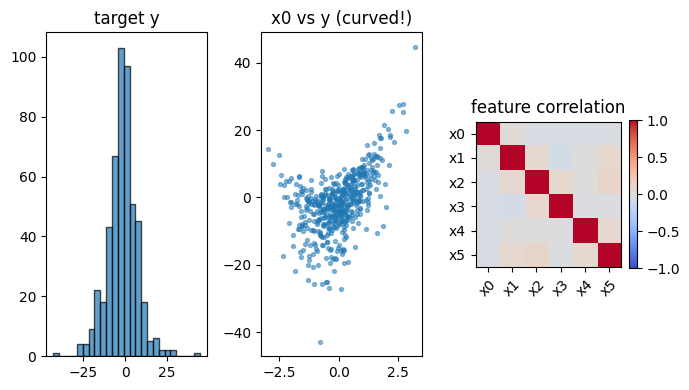

           x0      x1      x2      x3      x4      x5       y
count  500.00  500.00  500.00  500.00  500.00  500.00  500.00
mean    -0.04   -0.05   -0.05    0.03   -0.02   -0.03   -1.68
std      1.02    1.04    1.03    1.01    0.95    0.99    8.98
min     -2.96   -3.65   -2.65   -2.96   -2.76   -2.93  -42.83
25%     -0.71   -0.69   -0.80   -0.68   -0.63   -0.69   -6.64
50%     -0.03   -0.00   -0.08   -0.01    0.00    0.09   -1.33
75%      0.61    0.62    0.69    0.73    0.56    0.62    3.49
max      3.18    3.06    2.91    2.81    2.57    2.81   44.65


In [42]:
# 1. data (deliberately non-linear in the true DGP)
rng16 = np.random.default_rng(SEED)
X16 = rng16.normal(0, 1, (500, 6))
y16 = (5 * X16[:, 0] - 4 * X16[:, 1] + 2 * X16[:, 2]
       + 2.5 * X16[:, 0] ** 2 - 2 * X16[:, 1] ** 2
       + 1.5 * X16[:, 0] * X16[:, 1] - 2 * X16[:, 3] ** 2
       + rng16.normal(0, 2.5, 500))
feat16 = ["x0", "x1", "x2", "x3", "x4", "x5"]
df16 = pd.DataFrame(X16, columns=feat16)
df16["y"] = y16

# 2. EDA — three quick plots
fig, axes = plt.subplots(1, 3, figsize=(7, 4))
axes[0].hist(y16, bins=25, edgecolor="black", alpha=0.7)
axes[0].set_title("target y")
axes[1].scatter(X16[:, 0], y16, s=8, alpha=0.5)
axes[1].set_title("x0 vs y (curved!)")
corr16 = np.corrcoef(X16, rowvar=False)
im = axes[2].imshow(corr16, cmap="coolwarm", vmin=-1, vmax=1)
axes[2].set_title("feature correlation")
axes[2].set_xticks(range(6)); axes[2].set_xticklabels(feat16, rotation=45)
axes[2].set_yticks(range(6)); axes[2].set_yticklabels(feat16)
fig.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout(); plt.show()
print(df16.describe().round(2))


In [43]:
# 3. split once — test stays untouched until scoring
X16tr, X16te, y16tr, y16te = train_test_split(X16, y16, test_size=0.2,
                                              random_state=SEED)

# 4. four candidate models
models16 = {
    "Linear": LinearRegression(),
    "Ridge (α=1)": Pipeline([("sc", StandardScaler()),
                             ("m", Ridge(alpha=1.0))]),
    "Lasso (α=0.1)": Pipeline([("sc", StandardScaler()),
                               ("m", Lasso(alpha=0.1, max_iter=20000,
                                           random_state=SEED))]),
    "Poly(deg=2)": Pipeline([("pf", PolynomialFeatures(degree=2,
                                                       include_bias=False)),
                             ("sc", StandardScaler()),
                             ("m", Ridge(alpha=1.0))]),
}

# 5. metrics table
rows16 = {}
for name16, mdl16 in models16.items():
    mdl16.fit(X16tr, y16tr)
    p_tr = mdl16.predict(X16tr)
    p_te = mdl16.predict(X16te)
    rows16[name16] = {
        "MAE_train": mean_absolute_error(y16tr, p_tr),
        "MAE_test": mean_absolute_error(y16te, p_te),
        "RMSE_test": np.sqrt(mean_squared_error(y16te, p_te)),
        "R2_train": r2_score(y16tr, p_tr),
        "R2_test": r2_score(y16te, p_te),
    }
metrics16 = pd.DataFrame(rows16).T
print(metrics16.round(4))
best16 = metrics16["R2_test"].idxmax()
print(f"\nbest model by test R² → {best16}")


               MAE_train  MAE_test  RMSE_test  R2_train  R2_test
Linear            4.6555    4.7401     7.0494    0.4673   0.4396
Ridge (α=1)       4.6556    4.7400     7.0504    0.4673   0.4394
Lasso (α=0.1)     4.6639    4.7355     7.0568    0.4665   0.4384
Poly(deg=2)       1.8372    2.1547     2.6698    0.9345   0.9196

best model by test R² → Poly(deg=2)


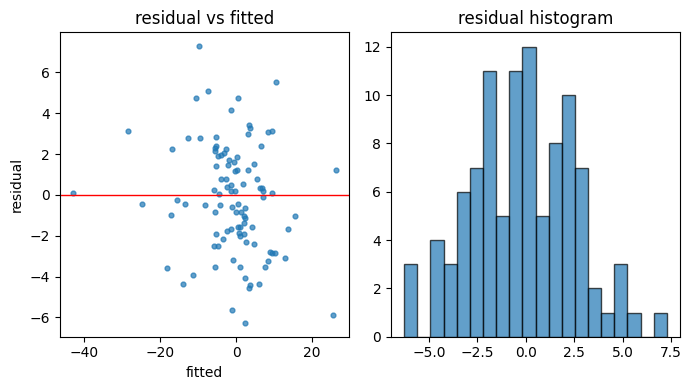

residual mean = -0.1856   std = 2.663
Durbin-Watson = 2.067  (≈ 2 → independent)
Jarque-Bera p = 0.835  (> 0.05 → roughly normal)


In [44]:
# 6. residual diagnostics of the winning model
best_model16 = models16[best16]
best_pred16 = best_model16.predict(X16te)
resid16 = y16te - best_pred16

fig, axes = plt.subplots(1, 2, figsize=(7, 4))
axes[0].scatter(best_pred16, resid16, s=12, alpha=0.7)
axes[0].axhline(0, color="r", lw=1)
axes[0].set_xlabel("fitted"); axes[0].set_ylabel("residual")
axes[0].set_title("residual vs fitted")
axes[1].hist(resid16, bins=20, edgecolor="black", alpha=0.7)
axes[1].set_title("residual histogram")
plt.tight_layout(); plt.show()

dw16 = durbin_watson(resid16)
jb16 = stats.jarque_bera(resid16)
print(f"residual mean = {resid16.mean():.4f}   std = {resid16.std():.3f}")
print(f"Durbin-Watson = {dw16:.3f}  (≈ 2 → independent)")
print(f"Jarque-Bera p = {jb16[1]:.3f}  (> 0.05 → roughly normal)")


**Insights from the pipeline.**

- **EDA already told the story:** the `x0 vs y` scatter curves, while the
  correlation heatmap only shows *linear* relationships (correlations ≈ 0 for
  the quadratic-only features) — a good reminder that `corr()` misses
  non-linear dependence.
- **Linear / Ridge / Lasso all plateau at the same mediocre $R^2$** — no
  amount of regularization can fix a model that lacks the right *features*:
  they cannot see $x^2$ or $x_0x_1$ terms at all.
- **`Poly(deg=2)` wins decisively** — the expanded feature space matches the
  true data-generating process, and Ridge on top of it keeps the 28 expanded
  coefficients stable.
- **Residual diagnostics of the winner look healthy** (DW ≈ 2, JB p > 0.05,
  cloud around 0) → the LINE assumptions hold, so we can trust the fit.
- **What you'd do next in real life:** `GridSearchCV` over `degree` and
  `alpha`, cross-validation instead of a single split, and a final untouched
  hold-out for the report.

**Section notes — project recipe:**

| Step | Code |
|---|---|
| EDA | `df.describe()`, hist, scatter, `np.corrcoef` heatmap |
| Split | `train_test_split(..., random_state=42)` |
| Models | `Pipeline([("pf"…), ("sc"…), ("m"…)])` — transformers inside the model |
| Metrics | `mean_absolute_error`, `np.sqrt(mean_squared_error)`, `r2_score` |
| Compare | one `pd.DataFrame` per model, pick by **test** $R^2$ |
| Validate | residual vs fitted + Durbin-Watson + Jarque-Bera |

---
## Quick revision sheet

**Formulas to know cold:**

| Concept | Formula |
|---|---|
| Simple linear model | $\hat y = b_0 + b_1x,\quad b_1=\dfrac{\sum(x-\bar x)(y-\bar y)}{\sum(x-\bar x)^2},\; b_0=\bar y-b_1\bar x$ |
| Multiple regression | $Y = X\beta,\quad \hat\beta=(X^\top X)^{-1}X^\top Y$ |
| Gradient update | $\beta \leftarrow \beta - \eta\nabla J(\beta)$ |
| MSE / RMSE / MAE | $\frac1n\sum e_i^2\;/\;\sqrt{\text{MSE}}\;/\;\frac1n\sum\lvert e_i\rvert$ |
| $R^2$ / adjusted | $1-\dfrac{SS_{res}}{SS_{tot}}\;/\;1-(1-R^2)\dfrac{n-1}{n-k-1}$ |
| Ridge cost | $\text{MSE} + \alpha\sum\beta_j^2$ → $(X^\top X+\alpha I)^{-1}X^\top Y$ |
| Lasso cost | $\text{MSE} + \alpha\sum\lvert\beta_j\rvert$ (subgradient $\operatorname{sign}(\beta)$) |
| ElasticNet cost | $\text{MSE} + \alpha\big(\rho\sum\lvert\beta_j\rvert+(1-\rho)\sum\beta_j^2\big)$ |
| Bias–variance | total error $=$ bias² + variance + noise |
| VIF | $\text{VIF}_j = 1/(1-R_j^2)$; < 5 ok, > 10 severe |
| Durbin-Watson | ≈ 2 → uncorrelated residuals |

**sklearn classes used in this notebook:**

| Task | Class |
|---|---|
| Split | `model_selection.train_test_split` |
| Linear models | `linear_model.LinearRegression`, `Ridge`, `Lasso`, `ElasticNet` |
| Scaling / features | `preprocessing.StandardScaler`, `PolynomialFeatures` |
| Chaining | `pipeline.Pipeline` |
| Metrics | `metrics.mean_absolute_error`, `mean_squared_error`, `r2_score` |
| Learning curve | `model_selection.learning_curve` |
| Filters | `feature_selection.VarianceThreshold`, `SelectKBest(chi2/f_classif/f_regression)` |
| Wrappers | `feature_selection.RFE`, `RFECV` |
| Embedded | `feature_selection.SelectFromModel(Lasso)`, `RandomForestRegressor.feature_importances_` |
| Inference / diagnostics | `statsmodels.api.OLS`, `sm.add_constant`, `statsmodels...durbin_watson` |

> **Interview short-list:** normal equations vs gradient descent · why scale
> before GD · batch vs stochastic vs mini-batch · LINE assumptions and their
> plots · $R^2$ vs $R^2_{adj}$ · VIF = $1/(1-R^2)$ · why Lasso is sparse and
> Ridge is not · when ElasticNet beats both · leakage vs feature selection ·
> bias² + variance + noise.

---
**Next notebook:** `11_ml_classification.ipynb` — the same modelling
discipline with discrete targets: logistic regression, decision boundaries,
and classification metrics.

**Playlist:** https://www.youtube.com/playlist?list=PLKnIA16_RmvbAlyx4_rdtR66B7EHX5k3z